<div style="border-left:7px solid #1A59FD; background:#F3F6FF; padding:16px 20px; border-radius:4px; font-family:Segoe UI, Arial, sans-serif;">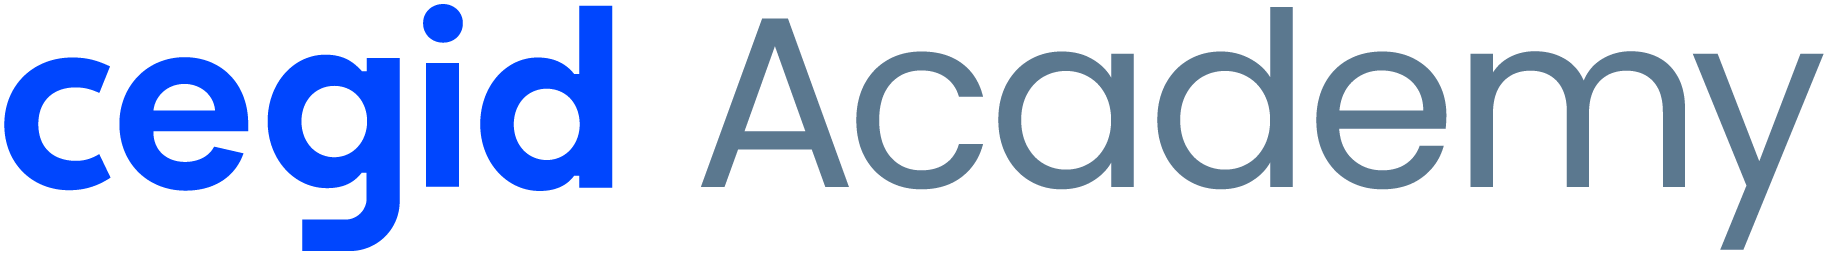<div style="font-size:22px; font-weight:700; color:#1A59FD; line-height:1.2;">Fase 2 &middot; Entendimento dos Dados</div><div style="font-size:14px; color:#0A2540; margin-top:4px;">Implementação de Modelos Analíticos com Python &nbsp;&middot;&nbsp; Projeto CRISP-DM · <i>Data Understanding</i> &nbsp;&middot;&nbsp; Versão <b>formandos</b> &nbsp;&middot;&nbsp; Apoio: <b>M1 · M2.01–M2.05</b></div><div style="margin-top:10px;"><span style="display:inline-block;background:#D6E2FF;color:#1A59FD;border:1px solid #D6E2FF;padding:3px 9px;margin:2px 3px 2px 0;border-radius:3px;font-size:12px;">1. Entendimento do Negócio</span><span style="display:inline-block;background:#1A59FD;color:#FFFFFF;font-weight:600;border:1px solid #1A59FD;padding:3px 9px;margin:2px 3px 2px 0;border-radius:3px;font-size:12px;">2. Entendimento dos Dados</span><span style="display:inline-block;background:#FFFFFF;color:#0A2540;border:1px solid #C9D6F5;padding:3px 9px;margin:2px 3px 2px 0;border-radius:3px;font-size:12px;">3. Preparação dos Dados</span><span style="display:inline-block;background:#FFFFFF;color:#0A2540;border:1px solid #C9D6F5;padding:3px 9px;margin:2px 3px 2px 0;border-radius:3px;font-size:12px;">4. Modelação</span><span style="display:inline-block;background:#FFFFFF;color:#0A2540;border:1px solid #C9D6F5;padding:3px 9px;margin:2px 3px 2px 0;border-radius:3px;font-size:12px;">5. Avaliação</span><span style="display:inline-block;background:#FFFFFF;color:#0A2540;border:1px solid #C9D6F5;padding:3px 9px;margin:2px 3px 2px 0;border-radius:3px;font-size:12px;">6. Deployment</span></div></div>

#### Identificação do projeto

| Campo | Preenchimento |
|---|---|
| **Projeto** | HR-Job-Change|
| **Grupo** |Grupo 3|
| **Formandos** |Cláudia Candeias - João Abreu |
| **Data** |18/10/2026 |
| **Dataset** |Dados_RH_Mudanca_Emprego.csv |

<div style="border-left:5px solid #1A59FD;background:#F3F6FF;color:#1F2A37;padding:10px 16px;margin:6px 0;border-radius:3px;font-family:Segoe UI, Arial, sans-serif;"><div style="font-weight:700;color:#1A59FD;font-size:13px;letter-spacing:0.5px;text-transform:uppercase;margin-bottom:4px;">Objetivo</div>Conhecer os dados antes de os transformar. Seguir o <b>workflow estruturado de AED</b> visto no M2.03 (e os gráficos do M1):<ul style="margin:4px 0 2px 0;"><li>Estrutura do dataset</li><li>Qualidade dos dados</li><li>Análise univariada</li><li>Análise bivariada</li><li>Análise multivariada</li></ul>No fim, cada problema encontrado deve dar origem a uma <b>decisão</b> para a Fase 3.</div>

<div style="border-left:5px solid #FF5B34;background:#FFF1EC;color:#1F2A37;padding:10px 16px;margin:6px 0;border-radius:3px;font-family:Segoe UI, Arial, sans-serif;"><div style="font-weight:700;color:#FF5B34;font-size:13px;letter-spacing:0.5px;text-transform:uppercase;margin-bottom:4px;">Atenção</div>Nesta fase <b>observa-se, não se transforma</b>. A limpeza, o encoding e o scaling são feitos na Fase 3 (Data Preparation). Visualizar ≠ decorar gráficos — visualizar = <b>interpretar dados</b>.</div>

<div style="border-left:5px solid #FF5B34;background:#FFF1EC;color:#1F2A37;padding:10px 16px;margin:6px 0;border-radius:3px;font-family:Segoe UI, Arial, sans-serif;"><div style="font-weight:700;color:#FF5B34;font-size:13px;letter-spacing:0.5px;text-transform:uppercase;margin-bottom:4px;">Data leakage na exploração</div>A AED é feita sobre o dataset completo para <b>compreender</b> os dados — isso está correto. O risco surge quando se <b>tomam decisões de modelação</b> com base em relações com o target calculadas com todas as linhas (incluindo as que vão ser o teste):<ul style="margin:4px 0 2px 0;"><li>escolher variáveis pela correlação ou pelo p-value com o target;</li><li>fixar limites de outliers, categorias raras ou intervalos de discretização a partir destes resultados e reutilizá-los tal e qual;</li><li>ajustar aqui um scaler, um PCA ou uma imputação e aproveitá-los na modelação.</li></ul>Nesta fase <b>regista-se</b> o que se observa; os valores concretos (medianas, limites, categorias, variáveis selecionadas) são <b>recalculados só no treino</b> na Fase 3.</div>

**Índice**

0. Configuração · 1. Recolha e descrição inicial · 2. Estrutura · 3. Qualidade · 4. Análise univariada · 5. Análise bivariada · 6. Análise multivariada · 7. Síntese e decisões

### 0. Configuração
<hr>

Preencher a configuração do projeto. Nas secções seguintes, as células marcadas como **[Classificação]**, **[Regressão]** ou **[Clustering]** só se aplicam a esse tipo de problema — mantenham apenas as que se aplicam ao vosso caso.

**0.1 Bibliotecas**
- Importar `numpy`, `pandas`, `matplotlib.pyplot`, `seaborn` e `scipy.stats`.
- Configurar `pd.set_option("display.max_columns", None)` e `sns.set_theme(style="whitegrid")`.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from pathlib import Path

pd.set_option("display.max_columns", None)
sns.set_theme(style="whitegrid")

**0.2 Configuração do projeto** (usar exatamente os mesmos valores no notebook 03)
- Criar as variáveis: `PROJETO` (nome curto, ex.: `"HR-Intern-Retention"`), `DATA_PATH` (caminho do dataset em `Data/input/`), `TARGET` (variável-alvo; em clustering `None` ou uma variável de referência), `PROBLEM_TYPE` (`"classificacao"`, `"regressao"` ou `"clustering"`), `ID_COLS` (lista de identificadores), `RANDOM_STATE = 42` e `TEST_SIZE = 0.2`.

In [2]:
PROJETO = "HR-Job-Change"
DATA_PATH = "Data/input/Dados_RH_Mudanca_Emprego.csv"
TARGET = "procura_mudanca_emprego"
PROBLEM_TYPE = "classificacao" # binaria (sim/nao) 
ID_COLS = ["id_candidato"]
RANDOM_STATE = 42
TEST_SIZE = 0.2

**0.3 Estrutura de pastas**
- Criar (se não existirem) as pastas `Data/input`, `Data/output`, `Data/analytics` e `Data/models` — sugestão: `pathlib.Path(...).mkdir(parents=True, exist_ok=True)`.
- (Opcional) Criar uma função `guardar_figura(nome)` que grava o gráfico atual em `Data/analytics/`.

In [3]:
PASTAS = ["Data/input", "Data/output", "Data/analytics", "Data/models"]
for pasta in PASTAS:
    Path(pasta).mkdir(parents=True, exist_ok=True)

def guardar_figura(nome):
    caminho = Path("Data/analytics") / f"{nome}.png"
    plt.savefig(caminho, dpi=150, bbox_inches="tight")
    print(f"Figura guardada em: {caminho}")

### 1. Recolha e descrição inicial dos dados
<hr>

- Origem do dataset (fonte, link, data de extração)
- Número de registos e de variáveis
- O que representa cada linha (unidade de análise)?
- Tipo de variáveis (numéricas, categóricas, temporais, texto)
- Unidade de medida de cada variável (€, %, meses, toneladas, …)

***Objetivo:*** perceber "o que tenho em mãos".

**1.1 Carregar o dataset**
- Ler o ficheiro com `pd.read_csv` (ou `pd.read_excel`) para um DataFrame `df`.
- Mostrar o número de registos e de variáveis (`.shape`) e as primeiras linhas (`.head()`).

In [4]:
df = pd.read_csv(DATA_PATH)

display(df.shape)
display(df.head())

(19158, 14)

,id_candidato,cidade,indice_desenvolvimento_cidade,genero,experiencia_relevante,inscricao_universidade,nivel_educacao,area_formacao,anos_experiencia,dimensao_empresa,tipo_empresa,anos_desde_ultimo_emprego,horas_formacao,procura_mudanca_emprego
0,760695,Zona_049,0.910,NaN,Com experiência relevante,Não inscrito,Licenciatura,"Ciência, Tecnologia, Engenharia e Matemática",6 anos,500 a 999,Empresa privada,1 ano,21,Não
1,789493,Zona_006,0.920,Feminino,Com experiência relevante,Não inscrito,Mestrado,Humanidades,Mais de 20 anos,100 a 500,Startup financiada,2 anos,74,Não
2,211612,Zona_007,0.924,NaN,Com experiência relevante,Não inscrito,Licenciatura,"Ciência, Tecnologia, Engenharia e Matemática",9 anos,10 a 49,Empresa privada,1 ano,94,Não
3,521686,Zona_065,0.624,Masculino,Com experiência relevante,Não inscrito,Mestrado,"Ciência, Tecnologia, Engenharia e Matemática",15 anos,10000 ou mais,Empresa privada,1 ano,75,Não
4,146611,Zona_030,0.698,Masculino,Sem experiência relevante,Não inscrito,Mestrado,"Ciência, Tecnologia, Engenharia e Matemática",12 anos,500 a 999,ONG,1 ano,157,Não


##### Análise e Interpretação

> *Quantos registos e variáveis existem? O que representa cada linha (unidade de análise)?*

**Resposta:**

- O dataset contém 19.158 registos e 14 variáveis. A unidade de análise é o candidato: cada linha corresponde a uma pessoa distinta (identificada por id_candidato), descrita pelas suas características demográficas, de formação e de percurso profissional, e pela variável-alvo `procura_mudanca_emprego`

<hr>

**1.2 Resumo das variáveis**
- Construir uma tabela com, para cada coluna: tipo (`dtypes`), nº de valores distintos (`nunique`) e 2–3 exemplos de valores.
- Usar esta tabela para preencher o dicionário de dados abaixo.

In [5]:
print(df.dtypes)

id_candidato                       int64
cidade                               str
indice_desenvolvimento_cidade    float64
genero                               str
experiencia_relevante                str
inscricao_universidade               str
nivel_educacao                       str
area_formacao                        str
anos_experiencia                     str
dimensao_empresa                     str
tipo_empresa                         str
anos_desde_ultimo_emprego            str
horas_formacao                     int64
procura_mudanca_emprego              str
dtype: object


In [6]:
print(df.nunique())

id_candidato                     19158
cidade                             123
indice_desenvolvimento_cidade       93
genero                               3
experiencia_relevante                2
inscricao_universidade               3
nivel_educacao                       5
area_formacao                        6
anos_experiencia                    22
dimensao_empresa                     8
tipo_empresa                         6
anos_desde_ultimo_emprego            6
horas_formacao                     241
procura_mudanca_emprego              2
dtype: int64


In [7]:
df.head(10)

,id_candidato,cidade,indice_desenvolvimento_cidade,genero,experiencia_relevante,inscricao_universidade,nivel_educacao,area_formacao,anos_experiencia,dimensao_empresa,tipo_empresa,anos_desde_ultimo_emprego,horas_formacao,procura_mudanca_emprego
0,760695,Zona_049,0.910,NaN,Com experiência relevante,Não inscrito,Licenciatura,"Ciência, Tecnologia, Engenharia e Matemática",6 anos,500 a 999,Empresa privada,1 ano,21,Não
1,789493,Zona_006,0.920,Feminino,Com experiência relevante,Não inscrito,Mestrado,Humanidades,Mais de 20 anos,100 a 500,Startup financiada,2 anos,74,Não
2,211612,Zona_007,0.924,NaN,Com experiência relevante,Não inscrito,Licenciatura,"Ciência, Tecnologia, Engenharia e Matemática",9 anos,10 a 49,Empresa privada,1 ano,94,Não
3,521686,Zona_065,0.624,Masculino,Com experiência relevante,Não inscrito,Mestrado,"Ciência, Tecnologia, Engenharia e Matemática",15 anos,10000 ou mais,Empresa privada,1 ano,75,Não
4,146611,Zona_030,0.698,Masculino,Sem experiência relevante,Não inscrito,Mestrado,"Ciência, Tecnologia, Engenharia e Matemática",12 anos,500 a 999,ONG,1 ano,157,Não
5,876389,Zona_086,0.896,Masculino,Com experiência relevante,Não inscrito,Ensino Secundário,NaN,13 anos,1000 a 4999,Setor público,2 anos,59,Não
6,849378,Zona_006,0.920,Masculino,Com experiência relevante,Não inscrito,Licenciatura,"Ciência, Tecnologia, Engenharia e Matemática",Mais de 20 anos,50 a 99,Empresa privada,Mais de 4 anos,56,Sim
7,751004,Zona_006,0.920,Masculino,Sem experiência relevante,Curso a tempo inteiro,Licenciatura,"Ciência, Tecnologia, Engenharia e Matemática",6 anos,NaN,NaN,1 ano,220,Não
8,630471,Zona_023,0.479,NaN,Com experiência relevante,Curso a tempo inteiro,Doutoramento,"Ciência, Tecnologia, Engenharia e Matemática",Mais de 20 anos,10000 ou mais,Empresa privada,Mais de 4 anos,44,Não
9,494403,Zona_056,0.878,Masculino,Sem experiência relevante,Não inscrito,Ensino Básico,NaN,6 anos,Menos de 10,Empresa privada,3 anos,12,Não


In [8]:
resumo = pd.DataFrame({
    "tipo": df.dtypes,
    "n_distintos": df.nunique(),
    "exemplos": [df[col].dropna().unique()[:5].tolist() for col in df.columns]
})

resumo

,tipo,n_distintos,exemplos
id_candidato,int64,19158,"[760695, 789493, 211612, 521686, 146611]"
cidade,str,123,"[Zona_049, Zona_006, Zona_007, Zona_065, Zona_..."
indice_desenvolvimento_cidade,float64,93,"[0.91, 0.92, 0.924, 0.624, 0.698]"
genero,str,3,"[Feminino, Masculino, Outro]"
experiencia_relevante,str,2,"[Com experiência relevante, Sem experiência re..."
inscricao_universidade,str,3,"[Não inscrito, Curso a tempo inteiro, Curso a ..."
nivel_educacao,str,5,"[Licenciatura, Mestrado, Ensino Secundário, Do..."
area_formacao,str,6,"[Ciência, Tecnologia, Engenharia e Matemática,..."
anos_experiencia,str,22,"[6 anos, Mais de 20 anos, 9 anos, 15 anos, 12 ..."
dimensao_empresa,str,8,"[500 a 999, 100 a 500, 10 a 49, 10000 ou mais,..."


##### Análise e Interpretação

> *Que tipos de variáveis existem (numéricas contínuas/discretas, categóricas nominais/ordinais, temporais, identificadores)? Algum tipo parece errado?*

**Resposta:**

- O dataset possui 14 variáveis
- O tipo do `id_candidato` está como número (`int64`) mas é um identificador (a média e soma não terão significado) - converter para texto
- `anos_experiencia`, `anos_desde_ultimo_emprego` e `dimensao_empresa` estão como texto, mas representam quantidades ordenadas - terão de ser convertidas para uma escala numérica ou ordinal na preparação dos dados
- `nivel_educacao` é texto mas tem uma ordem natural
<hr>

**Dicionário de dados** (completar)

| Coluna | Significado | Tipo de variável | Unidade / Exemplos / Notas |
|---|---|---|---|
| `id_candidato` |identificador unico do candidato |Identificador| Nº unico por linha (19 158 valores distintos) - não entra no modelo |
| `cidade` |Código da cidade/zona do candidato? |Categórica nominal |123 valores distintos! Problema na conversão (123 colunas novas...)|
| `indice_desenvolvimento_cidade` |Índice de desenvolvimento da cidade | Numérica contínua|93 valores distintos  |
| `genero` | Género de cada candidato | Categórica nominal| Feminino, Masculino e Outro|
| `experiencia_relevante` |	Se o candidato tem experiência relevante para a área |Categórica nominal (binária) |Com experiência relevante, Sem experiência relevante |
| `inscricao_universidade` | Se está inscrito num curso universitário e em que regime| Categórica nominal|Não inscrito, Curso a tempo inteiro, Curso a tempo parcial|
| `nivel_educacao` | Nível de educação mais alto concluído| Categórica ordinal |Ensino Básico > Ensino Secundário > Licenciatura > Mestrado > Doutoramento |
| `area_formacao` |Área de formação principal |Categórica nominal | 6 categorias únicas|
| `anos_experiencia` |Anos de experiência profissional |Categórica ordinal (guardada como texto) | 22 valores unicos e terá de ser convertido em número|
| `dimensao_empresa` |Número de funcionários da empresa atual |Categórica ordinal (guardada como texto) | 8 intervalos|
| `tipo_empresa` |Tipo da empresa atual |Categórica nominal | 6 categorias |
| `anos_desde_ultimo_emprego` |Tempo (em anos) desde o emprego anterior ou será tempo entre o emprego anterior e o atual? | Categórica ordinal (guardada como texto)| 6 categorias  |
| `horas_formacao` |Número de horas de formação concluídas |Numérica discreta | Em horas e 241 valores diferentes |
| `procura_mudanca_emprego` |Variável-alvo: se o candidato procura mudar de emprego | Categórica nominal (binária)|Sim / Não |


<div style="border-left:5px solid #0A2540;background:#F5F7FA;color:#1F2A37;padding:10px 16px;margin:6px 0;border-radius:3px;font-family:Segoe UI, Arial, sans-serif;"><div style="font-weight:700;color:#0A2540;font-size:13px;letter-spacing:0.5px;text-transform:uppercase;margin-bottom:4px;">Visto nas aulas</div>Tipos de variáveis (M1 · M2.01):<ul style="margin:4px 0 2px 0;"><li><b>Numérica contínua</b> — qualquer valor num intervalo (salário, idade, fare) → histograma, boxplot;</li><li><b>Numérica discreta</b> — contagens (nº de irmãos, meses) → histograma / bar plot;</li><li><b>Categórica nominal</b> — sem ordem (departamento, curso) → bar plot / countplot;</li><li><b>Categórica ordinal</b> — com ordem natural (nível de escolaridade, classe do bilhete);</li><li><b>Identificador</b> — não tem valor explicativo (ID) → excluir da modelação.</li></ul></div>

### 2. Análise da estrutura dos dados
<hr>

- `df.head()`, `df.info()`, `df.describe()`
- Os tipos de dados estão corretos? (ex.: datas lidas como texto, números como `object`)
- Existem colunas irrelevantes, identificadores ou colunas constantes?
- Existem variáveis que **não estariam disponíveis no momento da previsão** (risco de *data leakage*)?

***Objetivo:*** verificar problemas estruturais.

**2.1 Tipos e não-nulos**
- Aplicar `df.info()`.

In [9]:
df.info() # colunas, tipos, nº de valores não-nulos

<class 'pandas.DataFrame'>
RangeIndex: 19158 entries, 0 to 19157
Data columns (total 14 columns):
 #   Column                         Non-Null Count  Dtype  
---  ------                         --------------  -----  
 0   id_candidato                   19158 non-null  int64  
 1   cidade                         19158 non-null  str    
 2   indice_desenvolvimento_cidade  19158 non-null  float64
 3   genero                         14650 non-null  str    
 4   experiencia_relevante          19158 non-null  str    
 5   inscricao_universidade         18772 non-null  str    
 6   nivel_educacao                 18698 non-null  str    
 7   area_formacao                  16345 non-null  str    
 8   anos_experiencia               19093 non-null  str    
 9   dimensao_empresa               13220 non-null  str    
 10  tipo_empresa                   13018 non-null  str    
 11  anos_desde_ultimo_emprego      18735 non-null  str    
 12  horas_formacao                 19158 non-null  int64  
 1

In [10]:
df.describe().T # estatisticas de todas as colunas

,count,mean,std,min,25%,50%,75%,max
id_candidato,19158.0,547509.220430,259482.271599,100000.000,323343.50,546871.000,770871.50,999982.000
indice_desenvolvimento_cidade,19158.0,0.828848,0.123362,0.448,0.74,0.903,0.92,0.949
horas_formacao,19158.0,65.366896,60.058462,1.000,23.00,47.000,88.00,336.000


In [11]:
df.head()

,id_candidato,cidade,indice_desenvolvimento_cidade,genero,experiencia_relevante,inscricao_universidade,nivel_educacao,area_formacao,anos_experiencia,dimensao_empresa,tipo_empresa,anos_desde_ultimo_emprego,horas_formacao,procura_mudanca_emprego
0,760695,Zona_049,0.910,NaN,Com experiência relevante,Não inscrito,Licenciatura,"Ciência, Tecnologia, Engenharia e Matemática",6 anos,500 a 999,Empresa privada,1 ano,21,Não
1,789493,Zona_006,0.920,Feminino,Com experiência relevante,Não inscrito,Mestrado,Humanidades,Mais de 20 anos,100 a 500,Startup financiada,2 anos,74,Não
2,211612,Zona_007,0.924,NaN,Com experiência relevante,Não inscrito,Licenciatura,"Ciência, Tecnologia, Engenharia e Matemática",9 anos,10 a 49,Empresa privada,1 ano,94,Não
3,521686,Zona_065,0.624,Masculino,Com experiência relevante,Não inscrito,Mestrado,"Ciência, Tecnologia, Engenharia e Matemática",15 anos,10000 ou mais,Empresa privada,1 ano,75,Não
4,146611,Zona_030,0.698,Masculino,Sem experiência relevante,Não inscrito,Mestrado,"Ciência, Tecnologia, Engenharia e Matemática",12 anos,500 a 999,ONG,1 ano,157,Não


##### Análise e Interpretação

> *Os tipos de dados estão corretos? Há colunas com valores em falta?*

**Resposta:**

- `id_candidato` deveria ser texto e não int64
- `anos_experiencia`, `anos_desde_ultimo_emprego` e `dimensao_empresa` estão como texto, mas representam quantidades ordenadas
- `nivel_educacao` é texto mas tem ordem natural - Ensino Básico < Secundário < Licenciatura < Mestrado < Doutoramento
- Redundância a verificar: `cidade` (123 valores) e `indice_desenvolvimento_cidade` (93) estão ligadas - cada cidade tem sempre um único índice, ou seja, o índice é uma característica da cidade.
- valores em falta em 8 colunas - a variável-alvo não tem valores em falta!

<hr>

**2.2 Estatística descritiva geral**
- Aplicar `df.describe(include="all")` (dica: `.T` torna a tabela mais legível).

In [12]:
df.describe(include="all").T # estatisticas de todas as colunas

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
id_candidato,19158.0,NaN,NaN,NaN,547509.22043,259482.271599,100000.0,323343.5,546871.0,770871.5,999982.0
cidade,19158,123,Zona_006,4355,NaN,NaN,NaN,NaN,NaN,NaN,NaN
indice_desenvolvimento_cidade,19158.0,NaN,NaN,NaN,0.828848,0.123362,0.448,0.74,0.903,0.92,0.949
genero,14650,3,Masculino,13221,NaN,NaN,NaN,NaN,NaN,NaN,NaN
experiencia_relevante,19158,2,Com experiência relevante,13792,NaN,NaN,NaN,NaN,NaN,NaN,NaN
inscricao_universidade,18772,3,Não inscrito,13817,NaN,NaN,NaN,NaN,NaN,NaN,NaN
nivel_educacao,18698,5,Licenciatura,11598,NaN,NaN,NaN,NaN,NaN,NaN,NaN
area_formacao,16345,6,"Ciência, Tecnologia, Engenharia e Matemática",14492,NaN,NaN,NaN,NaN,NaN,NaN,NaN
anos_experiencia,19093,22,Mais de 20 anos,3286,NaN,NaN,NaN,NaN,NaN,NaN,NaN
dimensao_empresa,13220,8,50 a 99,3083,NaN,NaN,NaN,NaN,NaN,NaN,NaN


##### Análise e Interpretação

> *Há valores mínimos/máximos estranhos? Que variáveis têm escalas muito diferentes?*

**Resposta:**

- Não há valores estranhos (nem negativos, zeros)
- `id_candidato` é um identificador pelo que não devemos contabilizar estas estatísticas
- `horas_formacao` vai de 1 a 336 com média de 65 e mediana de 47 - a média acima da mediana indica uma distribuição assimétrica à direita (a maioria dos candidatos tem poucas horas de formação e uma minoria tem muitas)
- `indice_desenvolvimento_cidade`  varia entre 0,448 e 0,949, com média de 0,829 e mediana de 0,903 - a média fica abaixo da mediana: a distribuição é assimétrica à esquerda, com muitos candidatos em cidades muito desenvolvidas

<hr>

**2.3 Listas de variáveis, identificadores e colunas constantes**
- Criar as listas `num_cols` (numéricas) e `cat_cols` (categóricas), **sem** o target nem os `ID_COLS` — `select_dtypes`.
- Identificar colunas com um valor distinto por linha (possíveis identificadores) e colunas constantes.

In [13]:
excluir = ID_COLS + [TARGET] #sem o target nem identificador
X = df.drop(columns=excluir)

#numéricas + categóricas 
num_cols = X.select_dtypes(include="number").columns.tolist()
cat_cols = X.select_dtypes(exclude="number").columns.tolist()

print("Numéricas:", num_cols)
print("Categóricas:", cat_cols)

# colunas c/valor distinto
n_unicos = df.nunique()

# possíveis identificadores
possiveis_ids = n_unicos[n_unicos == len(df)].index.tolist()

# colunas constantes
constantes = n_unicos[n_unicos <= 1].index.tolist()

print("Possíveis identificadores:", possiveis_ids)
print("Colunas constantes:", constantes)
 

Numéricas: ['indice_desenvolvimento_cidade', 'horas_formacao']
Categóricas: ['cidade', 'genero', 'experiencia_relevante', 'inscricao_universidade', 'nivel_educacao', 'area_formacao', 'anos_experiencia', 'dimensao_empresa', 'tipo_empresa', 'anos_desde_ultimo_emprego']
Possíveis identificadores: ['id_candidato']
Colunas constantes: []


##### Análise e Interpretação

> *Que colunas devem ser excluídas da modelação (identificadores, constantes, redundantes, que revelam o alvo)?*

**Resposta:**

- `id_candidato` deve ser excluído - tem um valor distinto por linha (serve para identificar o candidato e não tem poder preditivo)
- não há colunas constantes pelo que não temos de as excluir
- há uma redundância entre `cidade` e `indice_desenvolvimento_cidade`
<hr>

<div style="border-left:5px solid #FF5B34;background:#FFF1EC;color:#1F2A37;padding:10px 16px;margin:6px 0;border-radius:3px;font-family:Segoe UI, Arial, sans-serif;"><div style="font-weight:700;color:#FF5B34;font-size:13px;letter-spacing:0.5px;text-transform:uppercase;margin-bottom:4px;">Sinais de alarme de leakage</div>Desconfiem de uma variável quando:<ul style="margin:4px 0 2px 0;"><li>tem correlação quase perfeita com o target ou separa as classes quase sem erro;</li><li>é registada <b>depois</b> do acontecimento que se quer prever (datas de saída, estado final, avaliações finais, montantes pagos no fim);</li><li>é o target escrito de outra forma (no Titanic, <code>alive</code>) ou uma transformação dele;</li><li>é um identificador ou uma data de registo que reflete a ordem de recolha e, por acaso, se relaciona com o target;</li><li>é um agregado calculado sobre um período que inclui o futuro (ex.: total de compras do ano, quando se prevê em março).</li></ul>Resultados “bons demais” (accuracy ou R² perto de 1) são, na maioria das vezes, sinal de leakage e não de um bom modelo.</div>

### 3. Análise de qualidade dos dados
<hr>

**Valores em falta** — quantos? em que variáveis? que percentagem por coluna? há padrão (MCAR / MAR / MNAR)?

**Valores duplicados** — existem? são legítimos (duas pessoas iguais) ou erros de registo?

**Inconsistências** — valores negativos onde não deveriam existir, percentagens > 100, categorias escritas de formas diferentes (`"HR"`, `"hr "`), unidades misturadas, **códigos de missing disfarçados** (999, −1, `fare = 0`).

**Colunas redundantes** — a mesma informação noutra forma (no Titanic: `class` = `pclass`, `embark_town` = `embarked`, e `alive` = **o próprio alvo disfarçado** → *leakage*).

***Objetivo:*** avaliar a qualidade dos dados.

**3.1 Valores em falta**
- Tabela com nº de nulos e % de nulos por coluna, ordenada — `isnull().sum()`, `isnull().mean()`.

In [14]:
# tabela de nulos: nº e % por coluna, ordenada

nulos = pd.DataFrame({
    "n_nulos": df.isnull().sum(),
    "pct_nulos": (df.isnull().mean() * 100).round(2)}).sort_values("pct_nulos", ascending=False)

display(nulos)

,n_nulos,pct_nulos
tipo_empresa,6140,32.05
dimensao_empresa,5938,30.99
genero,4508,23.53
area_formacao,2813,14.68
nivel_educacao,460,2.40
anos_desde_ultimo_emprego,423,2.21
inscricao_universidade,386,2.01
anos_experiencia,65,0.34
id_candidato,0,0.00
cidade,0,0.00


In [15]:
# só as colunas c/ nulos
display(nulos[nulos["n_nulos"] > 0])

,n_nulos,pct_nulos
tipo_empresa,6140,32.05
dimensao_empresa,5938,30.99
genero,4508,23.53
area_formacao,2813,14.68
nivel_educacao,460,2.40
anos_desde_ultimo_emprego,423,2.21
inscricao_universidade,386,2.01
anos_experiencia,65,0.34


##### Análise e Interpretação

> *Quantos valores faltam e em que variáveis? A ausência parece ao acaso (MCAR) ou ligada a outras variáveis (MAR/MNAR)?*

**Resposta:**

- as colunas `id_candidato`, `cidade`, `experiencia_relevante`, `indice_desenvolvimento_cidade`, `horas_formacao`, `procura_mudanca_emprego` não têm nulos;
- há 8 colunas com valores em falta (são categóricas): as mais afectadas são `tipo_empresa` (32 %), `dimensao_empresa` (31 %), `genero` (23,5 %) , `area_formacao` (15 %). As restantes têm menos de 3 %. 

<hr>

**3.2 Heatmap de valores nulos**
- `sns.heatmap(df.isnull(), cbar=False)`.

Figura guardada em: Data\analytics\02-3.2-heatmap_nulos.png


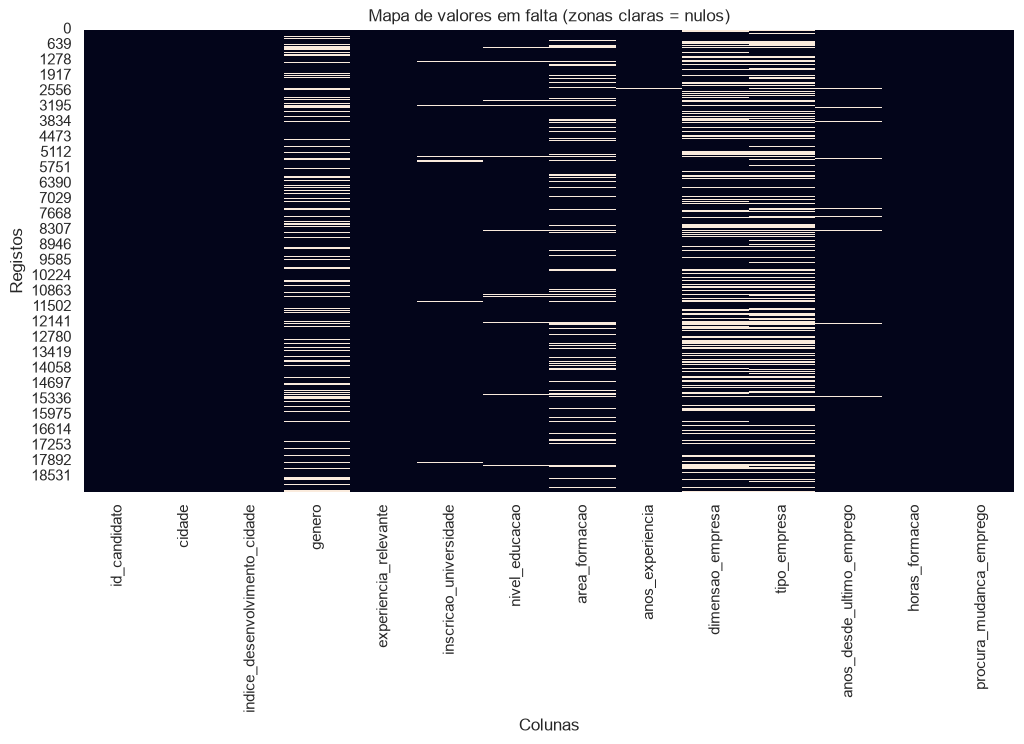

In [16]:
plt.figure(figsize=(12, 6))
sns.heatmap(df.isnull(), cbar=False)
plt.title("Mapa de valores em falta (zonas claras = nulos)") 
plt.xlabel("Colunas")
plt.ylabel("Registos")
guardar_figura("02-3.2-heatmap_nulos")
plt.show()

In [17]:
# quantas linhas têm pelo menos um valor em falta:

linhas_com_nulos = df.isnull().any(axis=1).sum()
print(f"Linhas com pelo menos 1 nulo: {linhas_com_nulos} "      
      f"({linhas_com_nulos / len(df):.1%})")

Linhas com pelo menos 1 nulo: 10203 (53.3%)


In [18]:
pd.crosstab(df["tipo_empresa"].isnull(), df["dimensao_empresa"].isnull(), margins=True)

# 5360 nulos nas duas, 780 nulos só tipo_empresa, 578 dimensao_empresa, 12440 não há nulos

dimensao_empresa,False,True,All
tipo_empresa,,,
False,12440,578,13018
True,780,5360,6140
All,13220,5938,19158


In [19]:
# com percentagens
pd.crosstab(df["tipo_empresa"].isnull(), df["dimensao_empresa"].isnull(), normalize="index").round(3)

dimensao_empresa,False,True
tipo_empresa,,
False,0.956,0.044
True,0.127,0.873


In [20]:
(df.groupby("experiencia_relevante")["dimensao_empresa"]
   .apply(lambda s: s.isnull().mean() * 100).round(1))

experiencia_relevante
Com experiência relevante    18.7
Sem experiência relevante    62.6
Name: dimensao_empresa, dtype: float64

In [21]:
nivel = df["nivel_educacao"].fillna("Em falta")

(df.groupby(nivel)["area_formacao"].apply(lambda s: s.isnull().mean() * 100).round(1))

nivel_educacao
Doutoramento           0.0
Em falta             100.0
Ensino Básico        100.0
Ensino Secundário    100.0
Licenciatura           0.2
Mestrado               0.1
Name: area_formacao, dtype: float64

In [22]:
# os nulos de genero coincidem com os da empresa?
empresa_em_falta = df["tipo_empresa"].isnull() | df["dimensao_empresa"].isnull()
display(pd.crosstab(df["genero"].isnull(), empresa_em_falta, normalize="index").round(3))

# taxa de "Sim" por nº de nulos na linha
n_nulos_linha = df.isnull().sum(axis=1)
display((df[TARGET] == "Sim").groupby(n_nulos_linha).agg(taxa_sim="mean", n="size").round(3))

col_0,False,True
genero,,
False,0.668,0.332
True,0.588,0.412


,taxa_sim,n
0,0.166,8955
1,0.211,3718
2,0.415,3654
3,0.377,1953
4,0.318,628
5,0.244,176
6,0.226,62
7,0.167,12


##### Análise e Interpretação

> *Os nulos concentram-se em certas colunas ou linhas? Há algum padrão?*

**Resposta:**

- `tipo_empresa` e `dimensao_empresa` falham quase sempre juntos pelo que não é MCAR. 
- a falta de `dimensao_empresa` é muito mais comum em quem não tem experiência relevante (63 %) do que em quem tem (19 %) - quem não tem experiência na área, não tem empresa para descrever -> MAR
- `nivel_educacao` e `area_formacao` também tendem a falhar juntas (quando `nivel_educacao` está em falta, `area_formacao` também está, em 100% dos casos)
- os nulos em `area_formacao` estão quase totalmente concentrados nos candidatos com Ensino Básico, Ensino Secundário ou sem nível de educação indicado (100 % de nulos em cada um destes grupos), contra menos de 0,3% nos candidatos com ensino superior
- os nulos de `genero` estão só fracamente ligados aos da empresa: 41% dos candidatos sem género também não têm dados da empresa, contra 33% dos que têm género
- a taxa de "Sim" muda com o nº de nulos por linha: 16,6% nas linhas sem nulos contra 41,5% nas linhas com 2 nulos - a própria ausência de dados é informativa
- mais de metade das linhas (53.3 %) tem um nulo pelo que não podemos simplesmente eliminar todos os nulos, o que iria significar perder metade dos dados
<hr>

**3.3 Duplicados**
- Contar linhas duplicadas (`duplicated().sum()`) e IDs repetidos.

In [23]:
print("Linhas duplicadas:", df.duplicated().sum())

#ID repetidos
print("IDs repetidos:", df["id_candidato"].duplicated().sum())

#duplicados ignorando o ID (mesmo perfil, candidatos diferentes)
print("Duplicados ignorando o ID:", df.drop(columns=ID_COLS).duplicated().sum())

Linhas duplicadas: 0
IDs repetidos: 0
Duplicados ignorando o ID: 49


##### Análise e Interpretação

> *Existem duplicados? São erros de registo ou casos legítimos?*

**Resposta:**

- não há linhas duplicadas nem IDs repetidos
- ignorando o ID há 49 linhas iguais, mas são candidatos distintos com o mesmo perfil, por isso mantêm-se 

<hr>

<div style="border-left:5px solid #FF5B34;background:#FFF1EC;color:#1F2A37;padding:10px 16px;margin:6px 0;border-radius:3px;font-family:Segoe UI, Arial, sans-serif;"><div style="font-weight:700;color:#FF5B34;font-size:13px;letter-spacing:0.5px;text-transform:uppercase;margin-bottom:4px;">Dados agrupados e dados temporais</div><ul style="margin:4px 0 2px 0;"><li><b>Várias linhas da mesma entidade</b> (o mesmo cliente, doente, estagiário ou máquina): com uma divisão aleatória, a mesma entidade fica no treino e no teste e o modelo é avaliado sobre casos que já “conhece”. A divisão tem de ser feita <b>por entidade</b> (<code>GroupShuffleSplit</code>, <code>GroupKFold</code>).</li><li><b>Dados com ordem temporal</b> (vendas, séries, registos datados): uma divisão aleatória usa o futuro para prever o passado. A divisão deve ser <b>cronológica</b> (treino = período mais antigo, teste = período mais recente) e a validação cruzada feita com <code>TimeSeriesSplit</code>.</li><li><b>Duplicados exatos</b> que fiquem um no treino e outro no teste inflacionam o resultado: tratam-se antes da divisão (Fase 3, secção 2).</li></ul>Registem na síntese (secção 7) se o vosso dataset tem alguma destas estruturas.</div>

**3.4 Intervalos das variáveis numéricas**
- Mostrar mínimo e máximo de cada numérica e assinalar as que têm valores negativos.

In [24]:
intervalos = df[num_cols].agg(["min", "max"]).T
display(intervalos)

#negativos e zeros / coluna
print("Valores negativos por coluna:")
print((df[num_cols] < 0).sum())

print("Valores iguais a 0 por coluna:")
print((df[num_cols] == 0).sum())

,min,max
indice_desenvolvimento_cidade,0.448,0.949
horas_formacao,1.000,336.000


Valores negativos por coluna:
indice_desenvolvimento_cidade    0
horas_formacao                   0
dtype: int64
Valores iguais a 0 por coluna:
indice_desenvolvimento_cidade    0
horas_formacao                   0
dtype: int64


##### Análise e Interpretação

> *Há valores impossíveis (negativos, % > 100, códigos como 999 ou 0 improvável)?*

**Resposta:**

- não há valores negativos nem zeros em nenhuma das 2 variáveis numéricas
- `indice_desenvolvimento_cidade` está entre 0,448 e 0,949, dentro do intervalo esperado de um índice
- `horas_formacao` varia entre 1 e 336 horas (não há valores improváveis como valores negativos ou 999)

Não é necessário fazer nenhuma correção!


<hr>

**3.5 Categorias escritas de formas diferentes**
- Para cada categórica, comparar o nº de categorias antes e depois de `str.strip().str.lower()` e listar as categorias.

In [25]:
resumo = []

for col in cat_cols:
    s = df[col].dropna().astype(str)
    antes = s.nunique()
    depois = s.str.strip().str.lower().nunique()
    resumo.append({"coluna": col, "categorias_antes": antes,
                   "categorias_depois": depois, "diferenca": antes - depois})

display(pd.DataFrame(resumo))

,coluna,categorias_antes,categorias_depois,diferenca
0,cidade,123,123,0
1,genero,3,3,0
2,experiencia_relevante,2,2,0
3,inscricao_universidade,3,3,0
4,nivel_educacao,5,5,0
5,area_formacao,6,6,0
6,anos_experiencia,22,22,0
7,dimensao_empresa,8,8,0
8,tipo_empresa,6,6,0
9,anos_desde_ultimo_emprego,6,6,0


In [26]:
# listar as categorias (cidade não, que tem 123!)
for col in cat_cols:
    if col != "cidade":
        print(f"\n{col}:")
        print(sorted(df[col].dropna().unique()))


genero:
['Feminino', 'Masculino', 'Outro']

experiencia_relevante:
['Com experiência relevante', 'Sem experiência relevante']

inscricao_universidade:
['Curso a tempo inteiro', 'Curso a tempo parcial', 'Não inscrito']

nivel_educacao:
['Doutoramento', 'Ensino Básico', 'Ensino Secundário', 'Licenciatura', 'Mestrado']

area_formacao:
['Artes', 'Ciência, Tecnologia, Engenharia e Matemática', 'Gestão e Negócios', 'Humanidades', 'Outro', 'Sem especialização']

anos_experiencia:
['1 ano', '10 anos', '11 anos', '12 anos', '13 anos', '14 anos', '15 anos', '16 anos', '17 anos', '18 anos', '19 anos', '2 anos', '20 anos', '3 anos', '4 anos', '5 anos', '6 anos', '7 anos', '8 anos', '9 anos', 'Mais de 20 anos', 'Menos de 1 ano']

dimensao_empresa:
['10 a 49', '100 a 500', '1000 a 4999', '10000 ou mais', '50 a 99', '500 a 999', '5000 a 9999', 'Menos de 10']

tipo_empresa:
['Empresa privada', 'ONG', 'Outro', 'Setor público', 'Startup em fase inicial', 'Startup financiada']

anos_desde_ultimo_emprego

##### Análise e Interpretação

> *Há categorias duplicadas por diferenças de escrita? Que correções serão necessárias na Fase 3?*

**Resposta:**

- não há categorias duplicadas por diferenças de escrita (em todas as colunas categóricas o nº de categorias é o mesmo antes e depois) pelo que não serão necessárias correções de escrita na fase 3
- correções de formato necessárias:
        -> `anos_experiencia` tem 22 categorias e `anos_desde_ultimo_emprego` representam quantidades escritas como texto (conversão para valores numéricos mas é necessário decidir os extremos)
        -> `dimensao_empresa` e `nivel_educacao` têm uma ordem natural, menor para maior, e podem ser codificadas como ordinais 

<hr>

<div style="border-left:5px solid #0A2540;background:#F5F7FA;color:#1F2A37;padding:10px 16px;margin:6px 0;border-radius:3px;font-family:Segoe UI, Arial, sans-serif;"><div style="font-weight:700;color:#0A2540;font-size:13px;letter-spacing:0.5px;text-transform:uppercase;margin-bottom:4px;">Visto nas aulas</div>Tipos de <i>missing data</i> (M3.02):<ul style="margin:4px 0 2px 0;"><li><b>MCAR</b> — em falta completamente ao acaso, sem padrão;</li><li><b>MAR</b> — a ausência depende de outras variáveis observadas;</li><li><b>MNAR</b> — a ausência depende do próprio valor em falta (ex.: salários altos não declarados).</li></ul>O tipo de missing condiciona a estratégia a adotar na Fase 3.</div>

### 4. Análise univariada
<hr>

**Variáveis numéricas** — média, mediana, desvio padrão, mínimo/máximo, assimetria (*skewness*), histogramas, boxplots, outliers (IQR e Z-score), distribuição unimodal ou multimodal.

**Variáveis categóricas** — frequência das categorias, categorias raras.

**Variável-alvo** — balanceamento das classes (classificação) ou distribuição (regressão). **Muito importante!**

***Objetivo:*** ganhar intuição sobre os dados.

**4.1 "Ficha de identidade" das numéricas (M2.03)**
- Tabela com média, mediana, moda, desvio padrão, IQR, amplitude, coeficiente de variação (%), `skew` e `kurtosis`.

In [27]:
def ficha(s):
    q1, q3 = s.quantile([0.25, 0.75])
    return pd.Series({
        "media": s.mean(),
        "mediana": s.median(),
        "moda": s.mode().iloc[0],
        "desvio_padrao": s.std(),
        "IQR": q3 - q1,
        "amplitude": s.max() - s.min(),
        "CV_%": s.std() / s.mean() * 100,
        "skew": s.skew(),
        "kurtosis": s.kurtosis()
    })

tabela = df[num_cols].apply(ficha).T.round(3)
display(tabela)

,media,mediana,moda,desvio_padrao,IQR,amplitude,CV_%,skew,kurtosis
indice_desenvolvimento_cidade,0.829,0.903,0.92,0.123,0.18,0.501,14.884,-0.995,-0.539
horas_formacao,65.367,47.000,28.00,60.058,65.00,335.000,91.879,1.819,3.841


##### Análise e Interpretação

> *Onde está o valor típico de cada variável? Há diferenças grandes entre média e mediana? Que variáveis são assimétricas (|skew| > 1) ou muito dispersas?*

**Resposta:**

- valor típico: `indice_desenvolvimento_cidade` ronda o 0.90 (mediana e moda); `horas_formacao` é 47 (mediana) com a moda mais baixa com 28 horas
- media vs mediana: `horas_formacao` a diferença é grande - a média é cerca de 39 % superior (alguns candidatos com muitas horas puxam a média para cima); `indice_desenvolvimento_cidade` a média fica abaixo da mediana, puxada pelas cidades menos desenvolvidas
- assimetria: as duas variáveis são assimétricas - `horas_formacao` é assimétrica à direita (skew = 1,82) e `indice_desenvolvimento_cidade` à esquerda (skew = -0,995 - quase no limite)
- dispersão: `horas_formacao` é muito dispersa - desvio padrão (60,1) quase igual à média e coeficiente de variação de 91,9 %. O `índice de desenvolvimento` é pouco disperso (CV = 14,9%)
- achatamento: a kurtosis de `horas_formacao` (3,84) indica caudas pesadas, isto é, mais valores extremos do que numa distribuição normal, o que é coerente com os outliers. O `indice_desenvolvimento_cidade` tem kurtosis negativa (-0,54), com caudas ligeiramente mais leves

<hr>

**4.2 Histogramas com KDE**
- Um histograma (`sns.histplot(..., kde=True)`) por variável numérica, com a média e a mediana assinaladas.

Figura guardada em: Data\analytics\02-4.2-histogramas_numericas.png


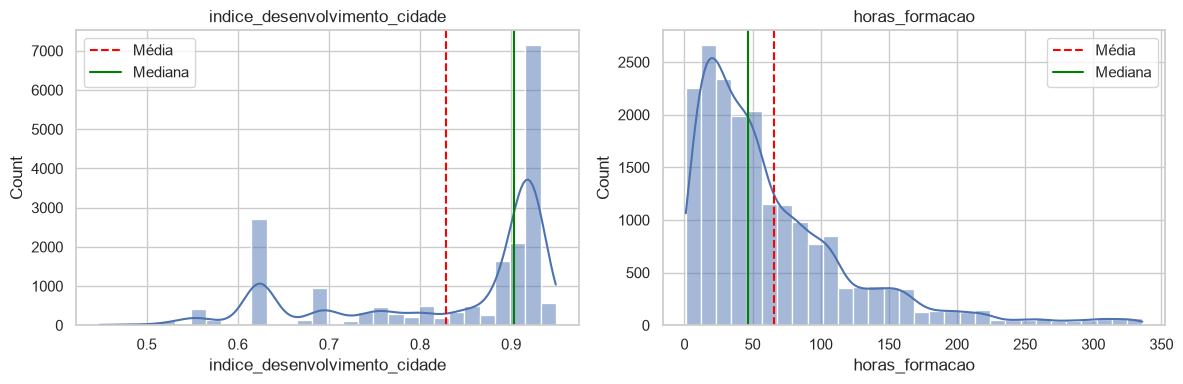

In [28]:
fig, axes = plt.subplots(1, len(num_cols), figsize=(12, 4))

for ax, col in zip(axes, num_cols):
    sns.histplot(df[col], kde=True, bins=30, ax=ax)
    ax.axvline(df[col].mean(), color="red", linestyle="--", label="Média")
    ax.axvline(df[col].median(), color="green", linestyle="-", label="Mediana")
    ax.set_title(col)
    ax.legend()

plt.tight_layout()
guardar_figura("02-4.2-histogramas_numericas")
plt.show()

##### Análise e Interpretação

> *As distribuições são unimodais ou multimodais? Simétricas ou assimétricas?*

**Resposta:**

- `indice_desenvolvimento_cidade` é multimodal e assimétrica à esquerda. A moda principal está perto de 0,92 (onde se concentra a maior parte dos candidatos) mas há picos secundários em 0,62 e 0,70. A média fica à esquerda da mediana puxada pela cauda de cidades menos desenvolvidas (cada pico corresponde a cidades com muitos candidatos)
-`horas_formacao` unimodal e assimétrica à direita - há um pico claro em valores baixos (cerca de 20 a 30 horas) e uma cauda longa até às 336 horas. A média fica à direita da mediana, o que confirma a assimetria positiva (skew = 1,82).



<hr>

<div style="border-left:5px solid #0A2540;background:#F5F7FA;color:#1F2A37;padding:10px 16px;margin:6px 0;border-radius:3px;font-family:Segoe UI, Arial, sans-serif;"><div style="font-weight:700;color:#0A2540;font-size:13px;letter-spacing:0.5px;text-transform:uppercase;margin-bottom:4px;">Visto nas aulas</div>Leitura (M2.03/M2.04): média ≫ mediana → assimetria à direita; |skew| > 1 → muito assimétrica; curtose alta → caudas pesadas (mais outliers); CV alto → grande dispersão relativa.</div>

**4.3 Boxplots**
- Um boxplot por variável numérica.

Figura guardada em: Data\analytics\02-4.3-boxplots_numericas.png


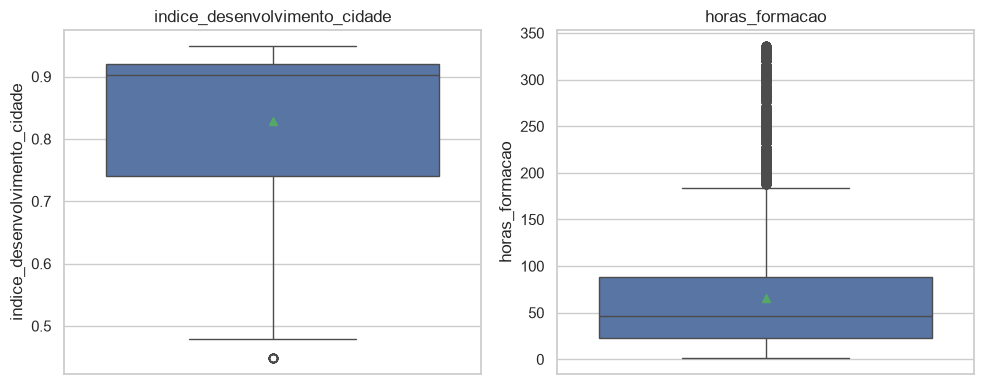

In [29]:
fig, axes = plt.subplots(1, len(num_cols), figsize=(10, 4))

for ax, col in zip(axes, num_cols):
    sns.boxplot(y=df[col], ax=ax, showmeans=True)
    ax.set_title(col)

plt.tight_layout()
guardar_figura("02-4.3-boxplots_numericas")
plt.show()

In [30]:
# contagem de outliers pelo IQR (os pontos para lá dos bigodes)
for col in num_cols:
    q1, q3 = df[col].quantile([0.25, 0.75])
    iqr = q3 - q1
    inferior, superior = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    n_baixo = (df[col] < inferior).sum()
    n_cima = (df[col] > superior).sum()
    print(f"{col}: limites IQR [{inferior:.3f}, {superior:.3f}] | "
          f"outliers abaixo: {n_baixo} | outliers acima: {n_cima} | "
          f"% do total: {(n_baixo + n_cima) / len(df):.1%}")

indice_desenvolvimento_cidade: limites IQR [0.470, 1.190] | outliers abaixo: 17 | outliers acima: 0 | % do total: 0.1%
horas_formacao: limites IQR [-74.500, 185.500] | outliers abaixo: 0 | outliers acima: 984 | % do total: 5.1%


##### Análise e Interpretação

> *Que variáveis apresentam pontos para lá dos bigodes? Parecem erros ou valores reais?*

**Resposta:**

- `horas_formacao`- tem 984 pontos acima do bigode superior (valores acima de 185,5 horas, ou seja, 5,1% dos registos), indo até às 336 horas. Parecem valores reais, e não erros pois parecem ser plausíveis (formações longas) e formam uma cauda contínua em vez de saltos isolados, coerente com a assimetria à direita (estes outliers talvez não devam ser removidos)
- `indice_desenvolvimento_cidade` - só tem 17 pontos abaixo do bigode inferior (0,1%) que corresponde a uma única cidade com índice baixo. Também parece um valor real (uma cidade pouco desenvolvida), e não um erro de registo

Nenhum dos pontos para lá dos bigodes parece um erro
<hr>

**4.4 Normalidade (M2.04)**
- QQ-plot de cada numérica (`stats.probplot(..., dist="norm", plot=ax)`).
- Teste de Shapiro-Wilk (`stats.shapiro`) numa tabela com W, p-value e conclusão.

Figura guardada em: Data\analytics\02-4.4-qqplots_numericas.png


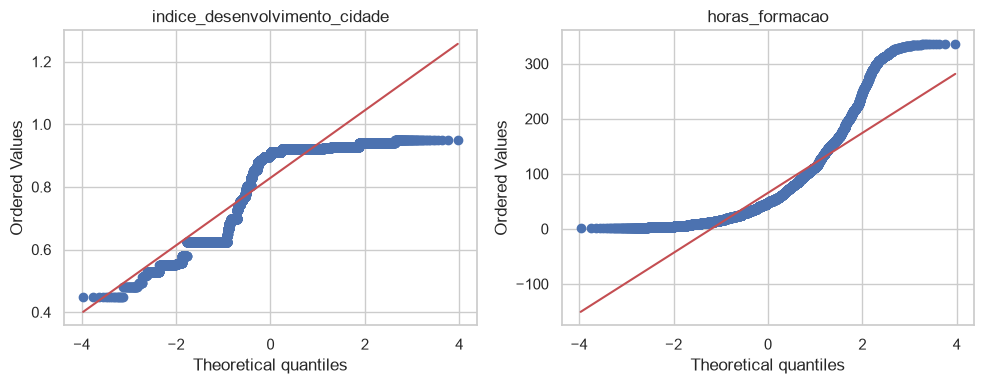

In [31]:
fig, axes = plt.subplots(1, len(num_cols), figsize=(10, 4))
for ax, col in zip(axes, num_cols):
    stats.probplot(df[col], dist="norm", plot=ax)
    ax.set_title(col)
plt.tight_layout()
guardar_figura("02-4.4-qqplots_numericas")
plt.show()

In [32]:
# Shapiro-Wilk - numa amostra de 5000, porque o teste é pouco fiável acima disso
linhas = []
for col in num_cols:
    amostra = df[col].sample(5000, random_state=RANDOM_STATE)
    w, p = stats.shapiro(amostra)
    conclusao = "aproxima-se da normal" if p > 0.05 else "rejeita a normalidade"
    linhas.append({"variavel": col, "W": round(w, 4), "p_value": p, "conclusao": conclusao})

display(pd.DataFrame(linhas))

,variavel,W,p_value,conclusao
0,indice_desenvolvimento_cidade,0.7721,4.427794e-64,rejeita a normalidade
1,horas_formacao,0.8271,7.143949e-59,rejeita a normalidade


##### Análise e Interpretação

> *Que variáveis se aproximam da normal? Os QQ-plots e os p-values concordam? Em qual confiam e porquê?*

**Resposta:**

- nenhuma das variáveis se aproxima da normal. O teste de Shapiro-Wilk rejeita a normalidade nas duas e os QQ-plots corroboram 
- `horas_formacao` forma uma curva em “S”, afastando-se da reta nas duas pontas: os valores baixos estão mais concentrados e os altos muito mais esticados do que numa normal, coerente com a assimetria à direita
- `indice_desenvolvimento_cidade` forma uma espécie de escadas/patamares. Este comportamento até faz sentido porque o índice só toma poucos valores distintos (um por cidade) e daí não seguir a reta.

- em termos de confiança o QQ-plot parece ser mais fiável do que o p-value: com muitos dados, o Shapiro-Wilk deteta desvios mais pequenos e rejeita quase sempre a normalidade, mesmo quando a distribuição é aproximadamente normal. Além disso, o teste só é fiável até cerca de 5000 observações, por isso foi feito numa amostra. Aqui, os dois métodos concordam, mas o QQ-plot mostra como e onde a distribuição se afasta da normal, o que o p-value não diz

<hr>

<div style="border-left:5px solid #0A2540;background:#F5F7FA;color:#1F2A37;padding:10px 16px;margin:6px 0;border-radius:3px;font-family:Segoe UI, Arial, sans-serif;"><div style="font-weight:700;color:#0A2540;font-size:13px;letter-spacing:0.5px;text-transform:uppercase;margin-bottom:4px;">Visto nas aulas</div>H0 do Shapiro-Wilk: os dados seguem uma distribuição normal. Se p &lt; 0,05 rejeita-se a normalidade → preferir mediana/IQR, testes não paramétricos (Mann-Whitney, Kruskal-Wallis, Spearman) ou uma transformação (log). Com amostras grandes o teste rejeita com facilidade: ler sempre em conjunto com o QQ-plot. Para n &gt; 5000 o <code>scipy</code> avisa que o p-value pode não ser exato.</div>

**4.5 Deteção de outliers (M2.04)**
- Criar uma função `conta_outliers(s)` que devolva os limites IQR e o nº de outliers por IQR (1,5×), Z-score (|z| > 3) e percentis (fora de P1–P99).
- Aplicar a todas as numéricas e apresentar numa tabela.

In [33]:
def conta_outliers(s):
    s = s.dropna()

   # IQR (1,5x)
    q1, q3 = s.quantile([0.25, 0.75])
    iqr = q3 - q1
    lim_inf, lim_sup = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    n_iqr = ((s < lim_inf) | (s > lim_sup)).sum()

    # Z-score (|z| > 3)
    z = (s - s.mean()) / s.std()
    n_z = (z.abs() > 3).sum()

    # percentis (fora de P1-P99)
    p1, p99 = s.quantile([0.01, 0.99])
    n_p = ((s < p1) | (s > p99)).sum()

    return pd.Series({
        "lim_inf_IQR": lim_inf, "lim_sup_IQR": lim_sup,
        "n_IQR": n_iqr, "n_Z": n_z, "n_P1_P99": n_p,
        "%_IQR": n_iqr / len(s) * 100,
        "%_Z": n_z / len(s) * 100,
        "%_P": n_p / len(s) * 100,
    })

tabela_outliers = df[num_cols].apply(conta_outliers).T.round(3)
display(tabela_outliers)

,lim_inf_IQR,lim_sup_IQR,n_IQR,n_Z,n_P1_P99,%_IQR,%_Z,%_P
indice_desenvolvimento_cidade,0.47,1.19,17.0,17.0,257.0,0.089,0.089,1.341
horas_formacao,-74.50,185.50,984.0,450.0,294.0,5.136,2.349,1.535


##### Análise e Interpretação

> *Os métodos concordam? Porquê? Quem são os outliers — erros ou informação rara mas real?*

**Resposta:**

- os métodos não concordam mas é o esperado - medem coisas diferentes
- IQR usa quartis, que não são afetados pelos extremos, por isso o limite é “apertado”. Em `horas_formacao` marca 984 outliers (5,1%), todos acima de 185,5 horas (lim_sup)
- Z-score usa a média e o desvio padrão, que são puxados pela própria cauda. Como `horas_formacao` é muito assimétrica, o desvio padrão é grande (60) e o limite sobe para cerca de 246 horas, marcando menos casos (450, ou 2,3%)
- percentis (P1–P99) marcam sempre cerca de 1% de cada lado por construção, independentemente dos dados, por isso não são um verdadeiro teste de “anormalidade”. Em `indice_desenvolvimento_cidade` marcam 257 casos, muitos deles apenas por haver muitos valores repetidos junto dos percentis
- `indice_desenvolvimento_cidade`: IQR e Z-score concordam (17 casos, 0,1%). São os candidatos de uma única cidade com índice 0,448, que é um valor real, e não um erro
- `horas_formacao`: o IQR é o método que melhor descreve a cauda, e o Z-score subestima-a por a distribuição não ser normal (como visto no QQ-plot). Os valores vão até 336 horas e formam uma cauda contínua, sem valores impossíveis nem saltos suspeitos



<hr>

<div style="border-left:5px solid #0A2540;background:#F5F7FA;color:#1F2A37;padding:10px 16px;margin:6px 0;border-radius:3px;font-family:Segoe UI, Arial, sans-serif;"><div style="font-weight:700;color:#0A2540;font-size:13px;letter-spacing:0.5px;text-transform:uppercase;margin-bottom:4px;">Visto nas aulas</div><ul style="margin:4px 0 2px 0;"><li><b>Z-score</b> funciona melhor em distribuições aproximadamente normais;</li><li><b>IQR</b> é mais robusto em distribuições assimétricas;</li><li>Nem todos os outliers são erros: podem representar informação rara mas importante — <b>ver quem são</b> (ex.: no Titanic, os outliers de <code>fare</code> são sobretudo passageiros de 1.ª classe).</li></ul></div>

**4.6 (Opcional) Transformação logarítmica**
- Para as variáveis com |skew| > 1 e sem negativos, comparar o histograma original com o de `np.log1p(...)` e o respetivo skew.

Candidatas à transformação: ['horas_formacao']
Figura guardada em: Data\analytics\02-4.6-transformacao_log.png


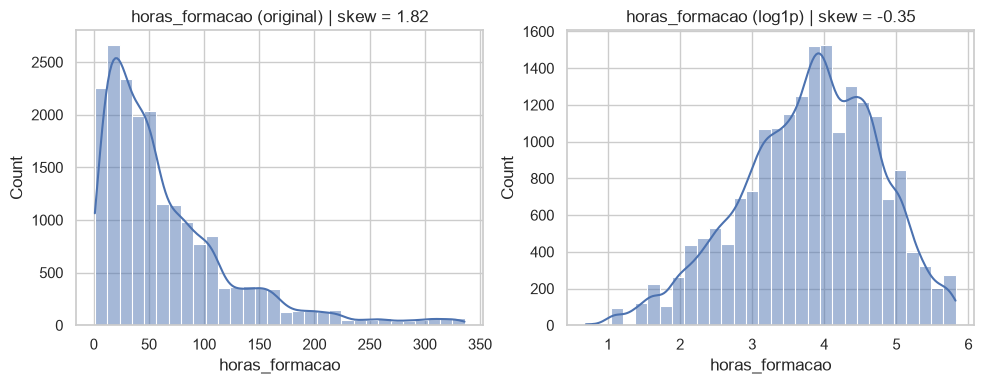

In [34]:
# variáveis com |skew| > 1 e sem valores negativos
candidatas = [c for c in num_cols
            if abs(df[c].skew()) > 1 and (df[c] >= 0).all()]
print("Candidatas à transformação:", candidatas)

fig, axes = plt.subplots(len(candidatas), 2, figsize=(10, 4 * len(candidatas)), squeeze=False)

for i, col in enumerate(candidatas):
    original = df[col]
    log = np.log1p(df[col])

    sns.histplot(original, kde=True, bins=30, ax=axes[i, 0])
    axes[i, 0].set_title(f"{col} (original) | skew = {original.skew():.2f}")

    sns.histplot(log, kde=True, bins=30, ax=axes[i, 1])
    axes[i, 1].set_title(f"{col} (log1p) | skew = {log.skew():.2f}")

plt.tight_layout()
guardar_figura("02-4.6-transformacao_log")
plt.show()

##### Análise e Interpretação

> *A transformação reduz a assimetria? Vale a pena aplicá-la na Fase 3?*

**Resposta:**

- só aplicamos a transformação a `horas_formacao` pois skew = 1,82, sem negativos
- sim, a transformação reduz a assimetria, skew passa de 1,82 para -0,35, e o histograma passa de uma cauda longa à direita para uma forma quase simétrica, em forma de sino
- `indice_desenvolvimento_cidade` não foi transformado pois o seu skew (-0,995) é negativo e o log não corrige assimetria à esquerda (piora ligeiramente). Além disso, o índice toma poucos valores distintos (um por cidade), por isso não ganha nada com a transformação.
- a aplicabilidade na fase 3 irá depender do modelo escolhido 


<hr>

**4.7 Variáveis categóricas (M2.03)**
- Para cada categórica: nº de categorias, moda, tabela de frequências (absolutas e %) e `countplot`.

In [35]:
resumo = pd.DataFrame({
    "n_categorias": df[cat_cols].nunique(),
    "moda": [df[c].mode()[0] for c in cat_cols],
    "% da moda": [round(df[c].value_counts(normalize=True).iloc[0] * 100, 1) for c in cat_cols],
})
display(resumo)

,n_categorias,moda,% da moda
cidade,123,Zona_006,22.7
genero,3,Masculino,90.2
experiencia_relevante,2,Com experiência relevante,72.0
inscricao_universidade,3,Não inscrito,73.6
nivel_educacao,5,Licenciatura,62.0
area_formacao,6,"Ciência, Tecnologia, Engenharia e Matemática",88.7
anos_experiencia,22,Mais de 20 anos,17.2
dimensao_empresa,8,50 a 99,23.3
tipo_empresa,6,Empresa privada,75.4
anos_desde_ultimo_emprego,6,1 ano,42.9



cidade (123 categorias)


,n,%
cidade,,
Zona_006,4355,22.7
Zona_065,2702,14.1
Zona_049,1533,8.0
Zona_014,1336,7.0
Zona_050,845,4.4
Zona_031,586,3.1
Zona_096,431,2.2
Zona_104,305,1.6
Zona_005,304,1.6


Figura guardada em: Data\analytics\02-4.7-countplot_cidade.png


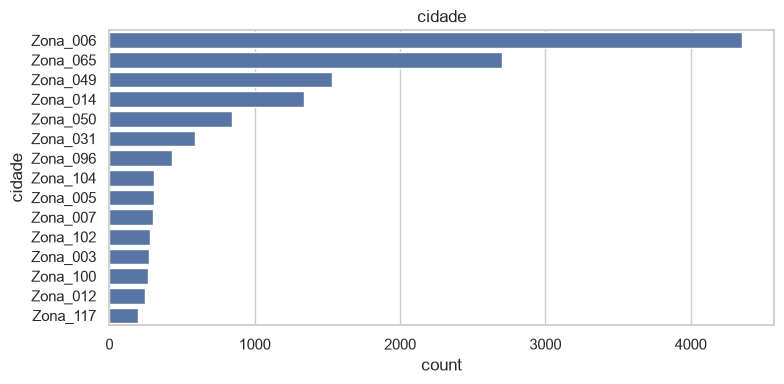


genero (3 categorias)


,n,%
genero,,
Masculino,13221,69.0
NaN,4508,23.5
Feminino,1238,6.5
Outro,191,1.0


Figura guardada em: Data\analytics\02-4.7-countplot_genero.png


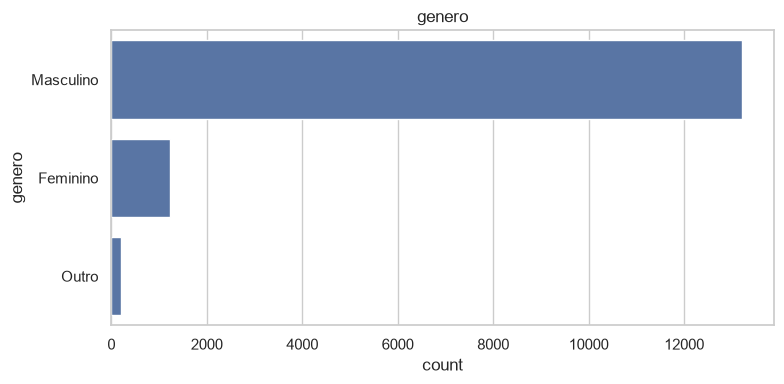


experiencia_relevante (2 categorias)


,n,%
experiencia_relevante,,
Com experiência relevante,13792,72.0
Sem experiência relevante,5366,28.0


Figura guardada em: Data\analytics\02-4.7-countplot_experiencia_relevante.png


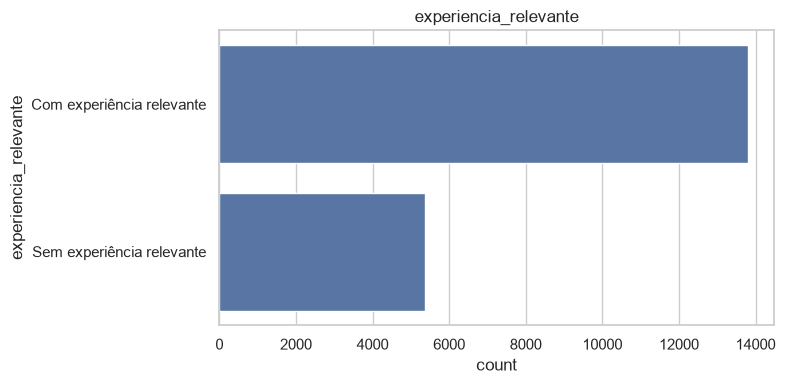


inscricao_universidade (3 categorias)


,n,%
inscricao_universidade,,
Não inscrito,13817,72.1
Curso a tempo inteiro,3757,19.6
Curso a tempo parcial,1198,6.3
NaN,386,2.0


Figura guardada em: Data\analytics\02-4.7-countplot_inscricao_universidade.png


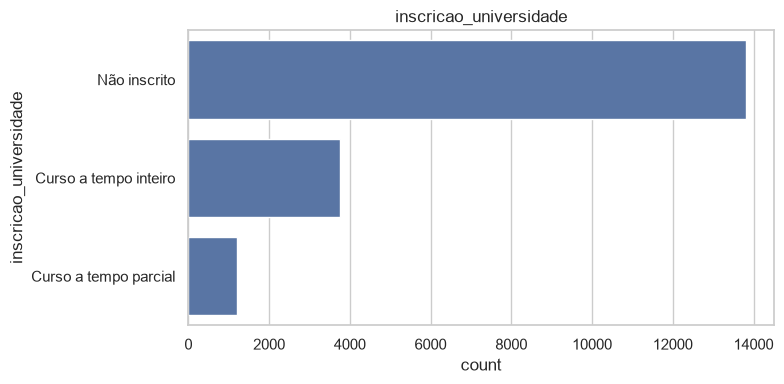


nivel_educacao (5 categorias)


,n,%
nivel_educacao,,
Licenciatura,11598,60.5
Mestrado,4361,22.8
Ensino Secundário,2017,10.5
NaN,460,2.4
Doutoramento,414,2.2
Ensino Básico,308,1.6


Figura guardada em: Data\analytics\02-4.7-countplot_nivel_educacao.png


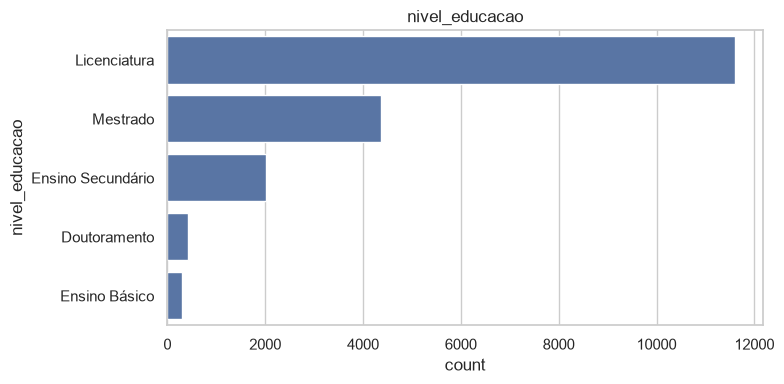


area_formacao (6 categorias)


,n,%
area_formacao,,
"Ciência, Tecnologia, Engenharia e Matemática",14492,75.6
NaN,2813,14.7
Humanidades,669,3.5
Outro,381,2.0
Gestão e Negócios,327,1.7
Artes,253,1.3
Sem especialização,223,1.2


Figura guardada em: Data\analytics\02-4.7-countplot_area_formacao.png


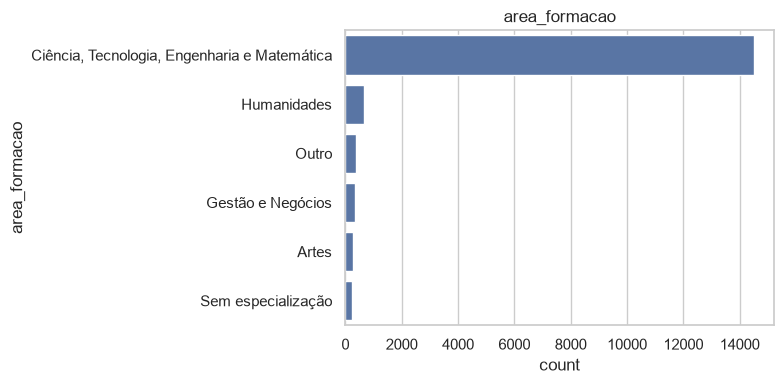


anos_experiencia (22 categorias)


,n,%
anos_experiencia,,
Mais de 20 anos,3286,17.2
5 anos,1430,7.5
4 anos,1403,7.3
3 anos,1354,7.1
6 anos,1216,6.3
2 anos,1127,5.9
7 anos,1028,5.4
10 anos,985,5.1
9 anos,980,5.1


Figura guardada em: Data\analytics\02-4.7-countplot_anos_experiencia.png


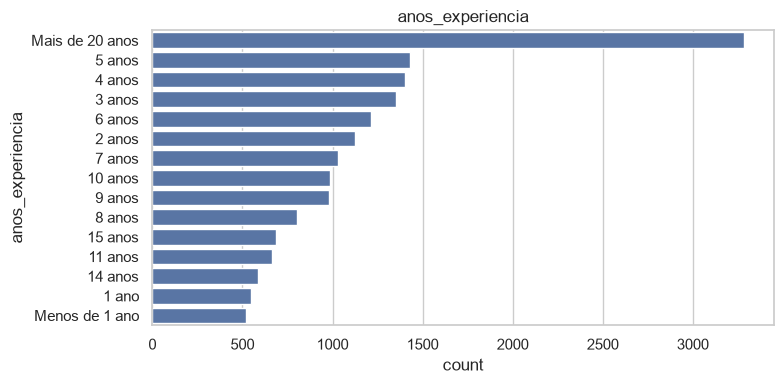


dimensao_empresa (8 categorias)


,n,%
dimensao_empresa,,
NaN,5938,31.0
50 a 99,3083,16.1
100 a 500,2571,13.4
10000 ou mais,2019,10.5
10 a 49,1471,7.7
1000 a 4999,1328,6.9
Menos de 10,1308,6.8
500 a 999,877,4.6
5000 a 9999,563,2.9


Figura guardada em: Data\analytics\02-4.7-countplot_dimensao_empresa.png


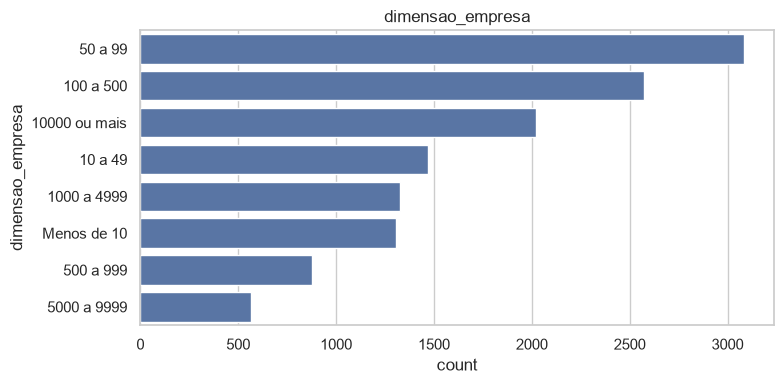


tipo_empresa (6 categorias)


,n,%
tipo_empresa,,
Empresa privada,9817,51.2
NaN,6140,32.0
Startup financiada,1001,5.2
Setor público,955,5.0
Startup em fase inicial,603,3.1
ONG,521,2.7
Outro,121,0.6


Figura guardada em: Data\analytics\02-4.7-countplot_tipo_empresa.png


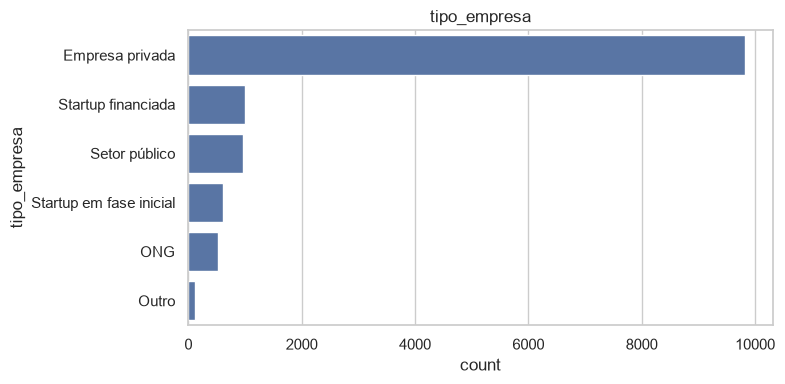


anos_desde_ultimo_emprego (6 categorias)


,n,%
anos_desde_ultimo_emprego,,
1 ano,8040,42.0
Mais de 4 anos,3290,17.2
2 anos,2900,15.1
Nunca,2452,12.8
4 anos,1029,5.4
3 anos,1024,5.3
NaN,423,2.2


Figura guardada em: Data\analytics\02-4.7-countplot_anos_desde_ultimo_emprego.png


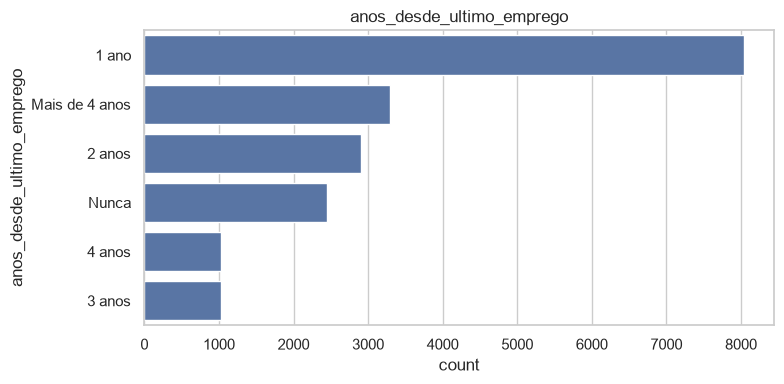

In [36]:
for col in cat_cols:
    freq = df[col].value_counts(dropna=False)
    tabela = pd.DataFrame({"n": freq, "%": (freq / len(df) * 100).round(1)})

    # só mostra as 15 mais frequentes (importante para cidade e anos_experiencia)
    top = tabela.head(15)
    print(f"\n{col} ({df[col].nunique()} categorias)")
    display(top)

    plt.figure(figsize=(8, 4))
    sns.countplot(data=df, y=col, order=df[col].value_counts().index[:15])
    plt.title(col)
    plt.tight_layout()
    guardar_figura(f"02-4.7-countplot_{col}")
    plt.show()

##### Análise e Interpretação

> *Há categorias raras ou dominantes? A cardinalidade é alta?*

**Resposta:**

- várias variáveis têm uma categoria que domina: `area_formacao` -> 75,6% em Ciência, Tecnologia, Engenharia e Matemática, `inscricao_universidade` -> 72,1% “Não inscrito”, `experiencia_relevante` -> 72% com experiência, `genero` -> 69% Masculino e `nivel_educacao` -> 60,5% Licenciatura. Tudo isto faz sentido e reflete o perfil do dataset:  candidatos maioritariamente com formação superior em áreas técnicas e significa que algumas categorias têm pouca informação
- há categorias com menos de 5% dos registos, por exemplo `Ensino Básico` (1,6%), `Doutoramento` (2,2%), `Outro` em `genero` (1,0%), `Artes` (1,3%), `Sem especialização` (1,2%) e `Outro` em `tipo_empresa` (0,6%) - talvez possam ser agrupadas na Fase 3 (por exemplo numa categoria “Outro”) se causarem instabilidade nos modelos
- em termos de cardinalidade, `cidade` tem cardinalidade alta (123 categorias, das quais 106 pesam menos de 1% e 24 têm menos de 10 registos). A Zona_006 concentra 22,7% dos candidatos, e as 5 maiores concentram 56,2% -> codificar com one-hot criaria 123 colunas, por isso será preciso agrupar as zonas pequenas ou usar outra codificação (ou excluir a coluna, dado que o índice de desenvolvimento já a resume...)
- `anos_experiencia` (22 categorias) tem cardinalidade moderada, mas será convertida para numérica na Fase 3
- as restantes têm cardinalidade baixa (2 a 8 categorias) e podem ser codificadas sem problemas
- em `tipo_empresa` (32%), `dimensao_empresa` (31%) e `genero` (23,5%), os nulos formam a segunda ou terceira “categoria” mais frequente, o que reforça a necessidade de os tratar como categoria própria em vez de os apagar!!!

<hr>

**4.8 [Classificação] Balanceamento da variável-alvo**
- `value_counts()` (absoluto e `normalize=True`) e `countplot` do target.

,n,%
procura_mudanca_emprego,,
Não,14381,75.1
Sim,4777,24.9


Rácio: 3.01 : 1
Figura guardada em: Data\analytics\02-4.8-balanceamento_target.png


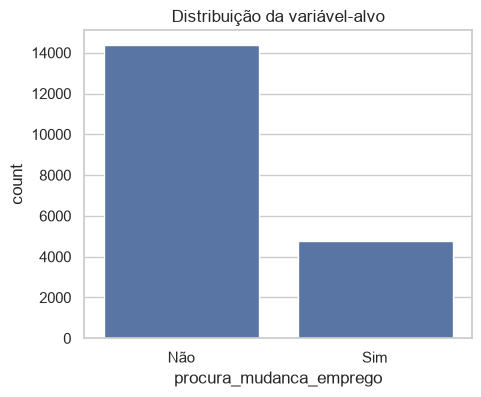

In [37]:
#contagens absolutas e percentagens
contagem = df[TARGET].value_counts()
percentagem = (df[TARGET].value_counts(normalize=True) * 100).round(1)
display(pd.DataFrame({"n": contagem, "%": percentagem}))

#rácio entre a classe maior e a menor
print("Rácio:", round(contagem.max() / contagem.min(), 2), ": 1")

plt.figure(figsize=(5, 4))
sns.countplot(data=df, x=TARGET, order=contagem.index)
plt.title("Distribuição da variável-alvo")
guardar_figura("02-4.8-balanceamento_target")
plt.show()

##### Análise e Interpretação

> *As classes estão equilibradas? Que consequências tem isso para a escolha das métricas e para a divisão treino/teste?*

**Resposta:**

- as classes não estão equilibradas: a classe “não” representa 75,1% dos candidatos e a classe “sim” apenas 24,9% (rácio de cerca de 3:1)- não é um desequilíbrio extremo, mas é suficiente para influenciar a avaliação

- a accuracy sozinha engana: um modelo que previsse sempre “não” teria 75,1% de accuracy sem identificar nenhum candidato que quer mudar de emprego - esse valor é a linha de base que os modelos têm de superar. Por isso, devem usar-se também métricas por classe (recall da classe "sim", precision, F1-score que vai equilibrar as 2 anteriores, ROC-AUC e a matriz de confusão para ver os erros de cada tipo)

- consequências para a divisão treino/teste: a divisão deve ser estratificada pelo alvo (stratify=y), para que treino e teste mantenham a proporção de 75/25. Sem isto, o conjunto de teste podia ficar, por acaso, com uma proporção diferente e os resultados ficavam menos comparáveis. O mesmo vale para a validação cruzada (StratifiedKFold).

<hr>

<div style="border-left:5px solid #FF5B34;background:#FFF1EC;color:#1F2A37;padding:10px 16px;margin:6px 0;border-radius:3px;font-family:Segoe UI, Arial, sans-serif;"><div style="font-weight:700;color:#FF5B34;font-size:13px;letter-spacing:0.5px;text-transform:uppercase;margin-bottom:4px;">Classes desbalanceadas</div>Se uma classe for muito maior do que a outra (ex.: 80/20), a <b>accuracy engana</b>: prever sempre a classe maioritária já dá 80%. Nesse caso usar <b>precision, recall, F1 e ROC-AUC</b> e <code>stratify=y</code> na divisão treino/teste. Também determina se são precisas técnicas como <code>class_weight</code> ou reamostragem (SMOTE) — M2.03. A reamostragem (SMOTE, oversampling, undersampling) faz-se <b>só no treino</b> e, na validação cruzada, dentro de cada fold (Pipeline do <code>imblearn</code>). Nunca antes da divisão: exemplos sintéticos criados a partir de linhas do teste passariam informação do teste para o treino. O teste mantém sempre a distribuição real.</div>

### 5. Análise bivariada
<hr>

**Variáveis vs Target**
- Classificação: boxplot/violin por classe, médias por grupo, taxa do target por categoria
- Regressão: scatter plot com o target, correlação com o target, boxplot do target por categoria

**Correlação entre variáveis**
- Matriz de correlação e heatmap
- Identificar multicolinearidade (variáveis explicativas fortemente correlacionadas entre si)

**Testes estatísticos (M2.05)** — intervalos de confiança e testes de hipóteses para confirmar as hipóteses da Fase 1.

***Objetivo:*** perceber as relações importantes.

**5.1 [Classificação] Numéricas por classe do target**
- Boxplot (`showmeans=True`) ou violinplot de cada numérica por classe do target.
- Tabela de médias e medianas por classe (`groupby`).

Figura guardada em: Data\analytics\02-5.1-boxplots_numericas_por_target.png


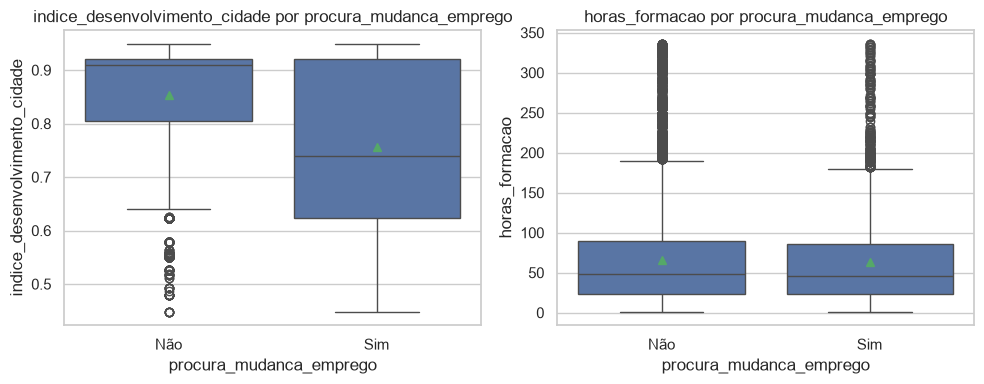

In [38]:
fig, axes = plt.subplots(1, len(num_cols), figsize=(10, 4))
for ax, col in zip(axes, num_cols):
    sns.boxplot(data=df, x=TARGET, y=col, showmeans=True, ax=ax)
    ax.set_title(f"{col} por {TARGET}")
plt.tight_layout()
guardar_figura("02-5.1-boxplots_numericas_por_target")
plt.show()

Figura guardada em: Data\analytics\02-5.1-violinplots_numericas_por_target.png


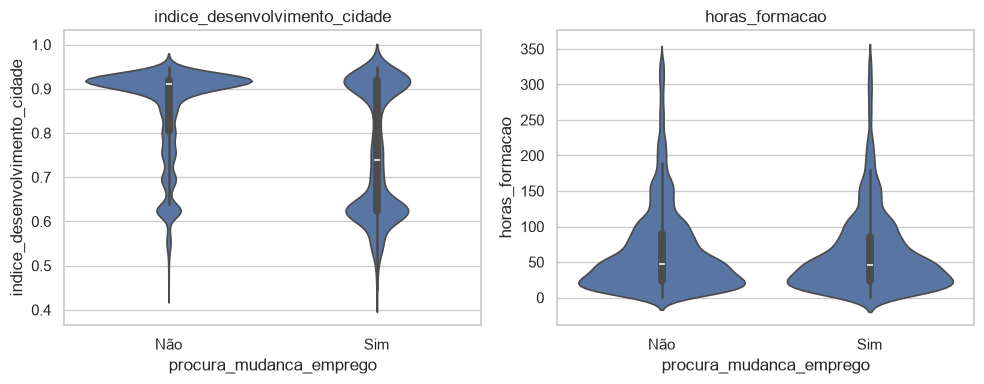

In [39]:
fig, axes = plt.subplots(1, len(num_cols), figsize=(10, 4))
for ax, col in zip(axes, num_cols):
    sns.violinplot(data=df, x=TARGET, y=col, ax=ax)
    ax.set_title(col)
plt.tight_layout()
guardar_figura("02-5.1-violinplots_numericas_por_target")
plt.show() #distribuição em cada classe

In [40]:
#médias e medianas por classe
for col in num_cols:
    display(df.groupby(TARGET)[col].agg(["mean", "median", "std"]).round(3))

,mean,median,std
procura_mudanca_emprego,,,
Não,0.853,0.91,0.105
Sim,0.756,0.74,0.143


,mean,median,std
procura_mudanca_emprego,,,
Não,66.114,48.0,60.939
Sim,63.118,46.0,57.274


##### Análise e Interpretação

> *Que variáveis parecem separar melhor as classes?*

**Resposta:**

- `indice_desenvolvimento_cidade` separa bem as classes - os candidatos que procuram mudar de emprego (“sim”) vivem em cidades menos desenvolvidas: média de 0,756 e mediana de 0,74, contra 0,853 e 0,91 nos que não procuram. A diferença nas medianas é de 0,17 e os boxplots quase não se sobrepõem. Os candidatos “sim” também têm maior dispersão (desvio padrão de 0,143 contra 0,105) --> H2 confirmada (Índice médio de 0,756 (Sim) vs 0,853 (Não); medianas de 0,74 vs 0,91)
- `horas_formacao` separa pouco - as médias (63,1 vs 66,1) e as medianas (46 vs 48) são quase iguais, e as distribuições sobrepõem-se praticamente por completo. Quem procura mudar de emprego tem, em média, ligeiramente menos horas de formação, mas a diferença é pequena face à dispersão (desvio padrão de cerca de 60) --> H3 não confirmada (média de 63,1 (Sim) vs 66,1 (Não); medianas de 46 vs 48)
- o índice de desenvolvimento da cidade é, das duas numéricas, a que mais ajuda a distinguir as classes. A significância estatística destas diferenças fica para a secção dos testes de hipóteses 

<hr>

**5.2 [Classificação] Taxa do target por categoria**
- `pd.crosstab(..., normalize="index")` para cada categórica.
- `countplot` com `hue=TARGET` e `barplot` da taxa média do target por categoria.


genero


procura_mudanca_emprego,Não,Sim
genero,,
Em falta,69.2,30.8
Feminino,73.7,26.3
Masculino,77.2,22.8
Outro,73.8,26.2


Figura guardada em: Data\analytics\02-5.2-taxa_target_genero.png


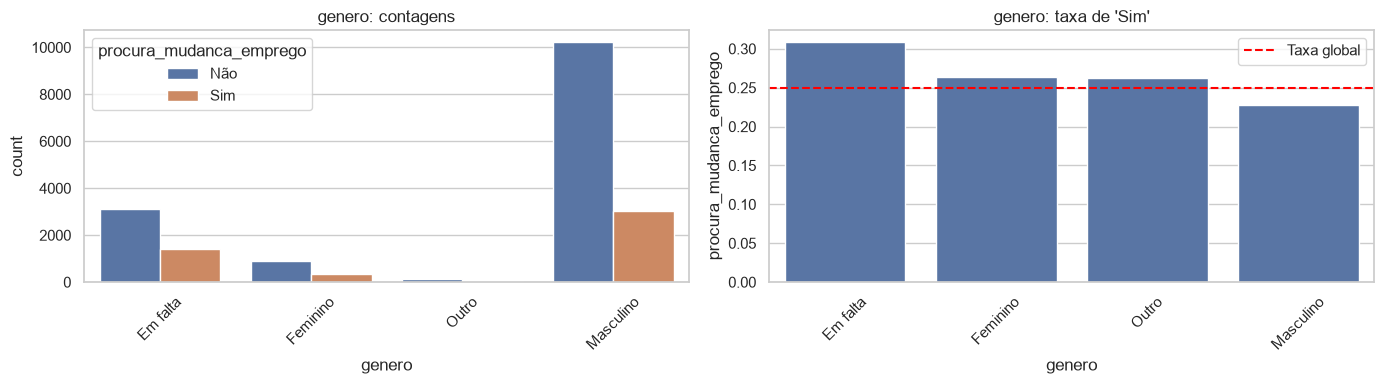


experiencia_relevante


procura_mudanca_emprego,Não,Sim
experiencia_relevante,,
Com experiência relevante,78.5,21.5
Sem experiência relevante,66.2,33.8


Figura guardada em: Data\analytics\02-5.2-taxa_target_experiencia_relevante.png


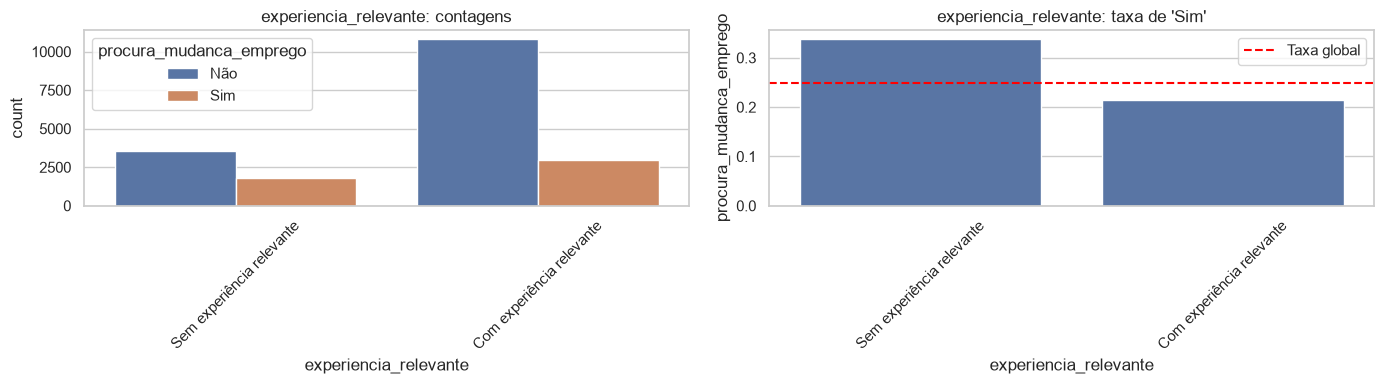


inscricao_universidade


procura_mudanca_emprego,Não,Sim
inscricao_universidade,,
Curso a tempo inteiro,61.9,38.1
Curso a tempo parcial,74.8,25.2
Em falta,68.1,31.9
Não inscrito,78.9,21.1


Figura guardada em: Data\analytics\02-5.2-taxa_target_inscricao_universidade.png


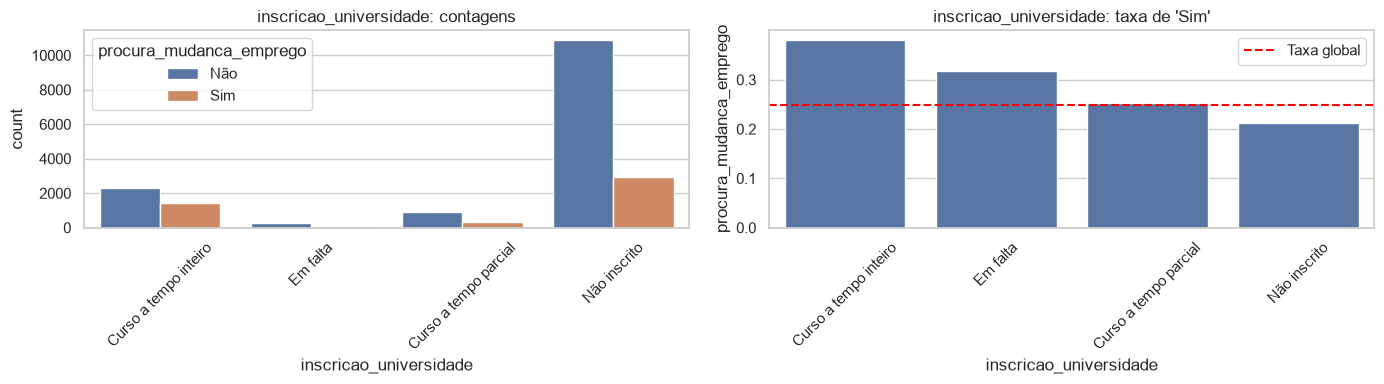


nivel_educacao


procura_mudanca_emprego,Não,Sim
nivel_educacao,,
Doutoramento,86.0,14.0
Em falta,77.4,22.6
Ensino Básico,86.7,13.3
Ensino Secundário,80.5,19.5
Licenciatura,72.0,28.0
Mestrado,78.6,21.4


Figura guardada em: Data\analytics\02-5.2-taxa_target_nivel_educacao.png


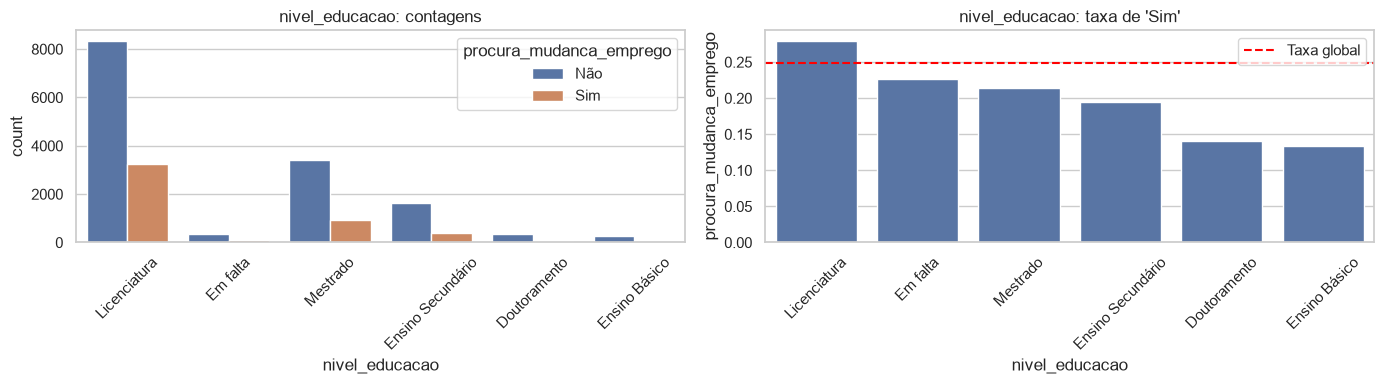


area_formacao


procura_mudanca_emprego,Não,Sim
area_formacao,,
Artes,79.1,20.9
"Ciência, Tecnologia, Engenharia e Matemática",73.8,26.2
Em falta,80.5,19.5
Gestão e Negócios,73.7,26.3
Humanidades,78.9,21.1
Outro,73.2,26.8
Sem especialização,75.3,24.7


Figura guardada em: Data\analytics\02-5.2-taxa_target_area_formacao.png


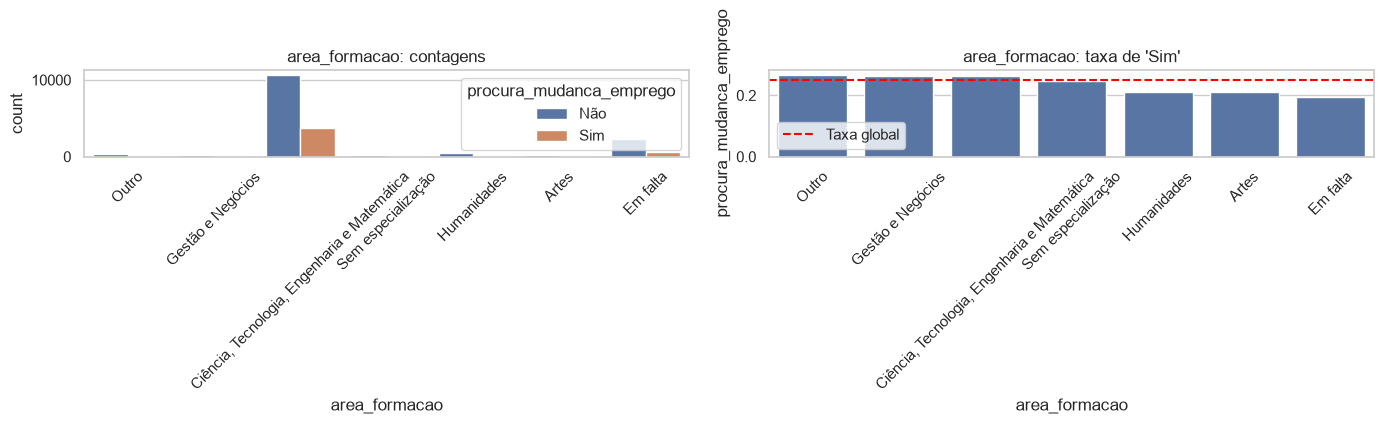


anos_experiencia


procura_mudanca_emprego,Não,Sim
anos_experiencia,,
1 ano,57.6,42.4
10 anos,79.0,21.0
11 anos,77.3,22.7
12 anos,81.4,18.6
13 anos,80.7,19.3
14 anos,81.7,18.3
15 anos,83.4,16.6
16 anos,85.8,14.2
17 anos,83.3,16.7


Figura guardada em: Data\analytics\02-5.2-taxa_target_anos_experiencia.png


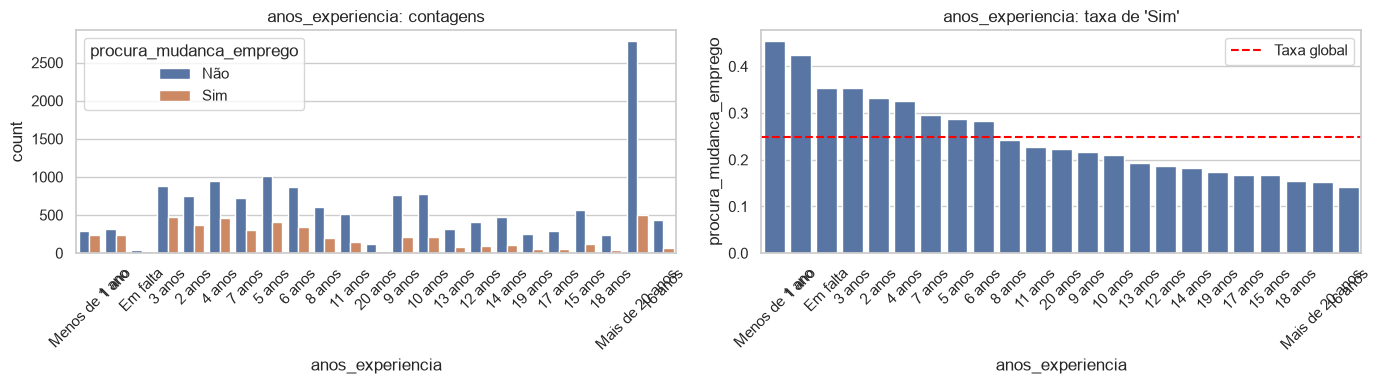


dimensao_empresa


procura_mudanca_emprego,Não,Sim
dimensao_empresa,,
10 a 49,76.6,23.4
100 a 500,83.9,16.1
1000 a 4999,84.9,15.1
10000 ou mais,80.9,19.1
50 a 99,82.3,17.7
500 a 999,82.7,17.3
5000 a 9999,81.9,18.1
Em falta,59.4,40.6
Menos de 10,82.9,17.1


Figura guardada em: Data\analytics\02-5.2-taxa_target_dimensao_empresa.png


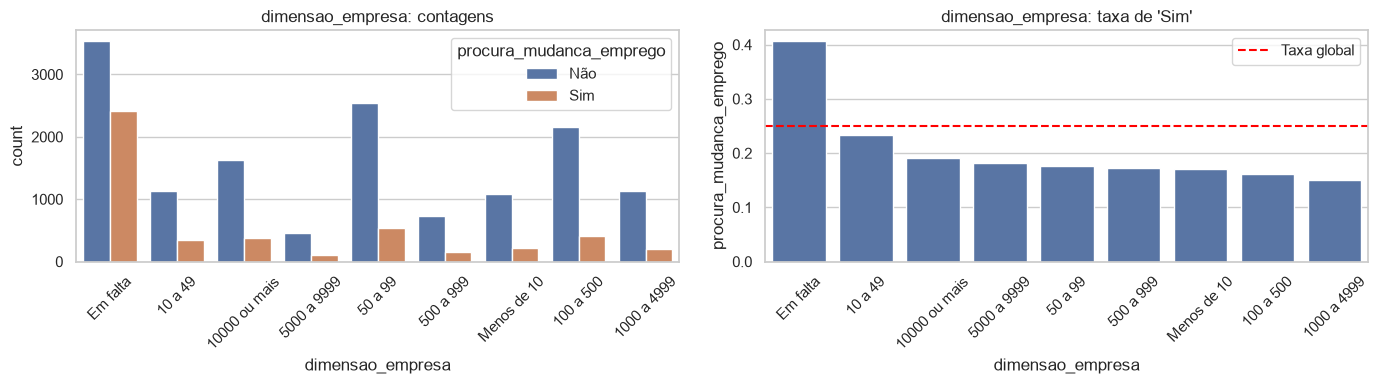


tipo_empresa


procura_mudanca_emprego,Não,Sim
tipo_empresa,,
Em falta,61.2,38.8
Empresa privada,81.9,18.1
ONG,81.4,18.6
Outro,76.0,24.0
Setor público,78.0,22.0
Startup em fase inicial,76.5,23.5
Startup financiada,86.0,14.0


Figura guardada em: Data\analytics\02-5.2-taxa_target_tipo_empresa.png


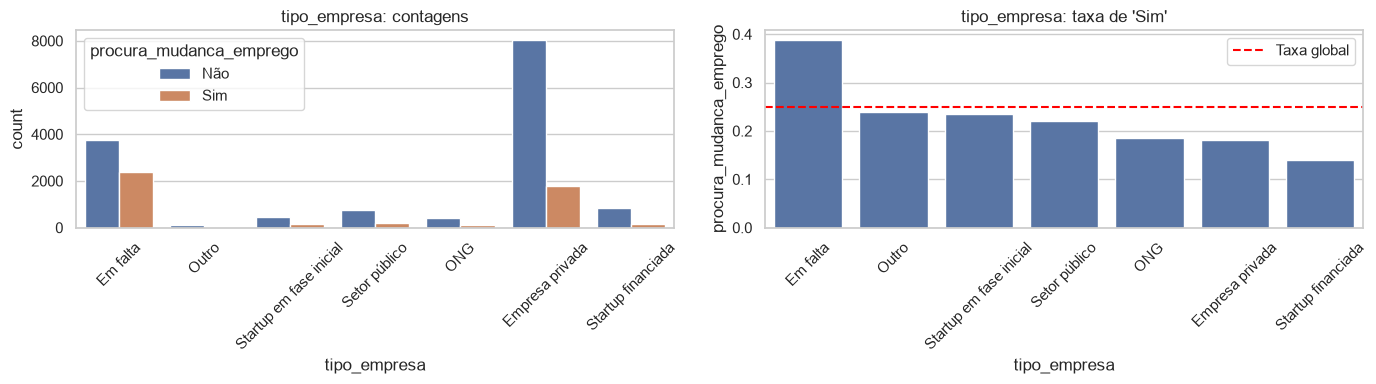


anos_desde_ultimo_emprego


procura_mudanca_emprego,Não,Sim
anos_desde_ultimo_emprego,,
1 ano,73.6,26.4
2 anos,75.9,24.1
3 anos,77.4,22.6
4 anos,77.8,22.2
Em falta,63.6,36.4
Mais de 4 anos,81.8,18.2
Nunca,69.9,30.1


Figura guardada em: Data\analytics\02-5.2-taxa_target_anos_desde_ultimo_emprego.png


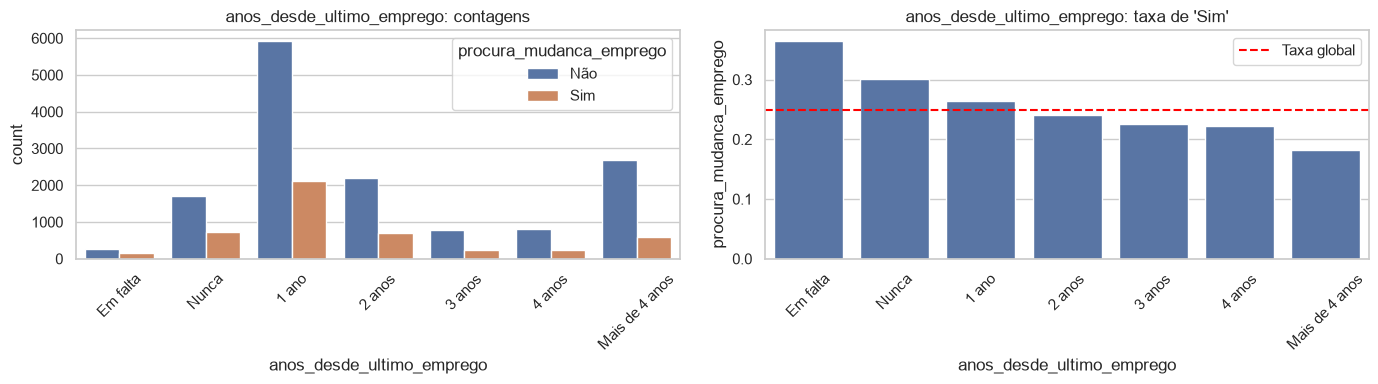

In [41]:
#alvo em 0/1 (1 = procura mudar de emprego), para poder calcular a taxa com a média
y = (df[TARGET] == "Sim").astype(int)

#colunas a analisar (a cidade fica de fora por ter 123 categorias; ver nota abaixo)
cols_5_2 = [c for c in cat_cols if c != "cidade"]

for col in cols_5_2:
    # Mostra os nulos como categoria própria
    categoria = df[col].fillna("Em falta")

    # 1) Taxa por categoria (crosstab em percentagem por linha)
    print(f"\n{col}")
    display((pd.crosstab(categoria, df[TARGET], normalize="index") * 100).round(1))

    # 2) Gráficos: contagens por classe e taxa de "Sim" por categoria
    ordem = y.groupby(categoria).mean().sort_values(ascending=False).index

    fig, axes = plt.subplots(1, 2, figsize=(14, 4))
    sns.countplot(x=categoria, hue=df[TARGET], order=ordem, ax=axes[0])
    axes[0].set_title(f"{col}: contagens")
    axes[0].tick_params(axis="x", rotation=45)

    sns.barplot(x=categoria, y=y, order=ordem, errorbar=None, ax=axes[1])
    axes[1].axhline(y.mean(), color="red", linestyle="--", label="Taxa global") #taxa global 24,9% - barra acima dela são categorias com mais procura de mudança que a média
    axes[1].set_title(f"{col}: taxa de 'Sim'")
    axes[1].tick_params(axis="x", rotation=45)
    axes[1].legend()

    plt.tight_layout()
    guardar_figura(f"02-5.2-taxa_target_{col}")
    plt.show()

In [42]:
# a cidade fica fora do ciclo (123 categorias): taxa de "Sim" nas 10 zonas com mais candidatos
zonas = (df.groupby("cidade")[TARGET]
           .agg(n="size", taxa_sim=lambda s: (s == "Sim").mean() * 100)
           .sort_values("n", ascending=False).head(10).round(1))
display(zonas)

,n,taxa_sim
cidade,,
Zona_006,4355,21.3
Zona_065,2702,59.1
Zona_049,1533,11.7
Zona_014,1336,10.0
Zona_050,845,23.6
Zona_031,586,10.4
Zona_096,431,13.2
Zona_104,305,10.2
Zona_005,304,17.1


##### Análise e Interpretação

> *Que categorias têm taxas muito diferentes? Confirma alguma hipótese da Fase 1?*

**Resposta:**

Variáveis com taxas muito diferentes entre categorias (comparar com a taxa global de 24,9%):

- taxas muito diferentes: `anos_experiencia` (de 45,4% para menos de 1 ano a cerca de 15% para mais de 15 anos), `experiencia_relevante` (33,8% sem vs 21,5% com), `inscricao_universidade` (38,1% a tempo inteiro vs 21,1% não inscritos) e, sobretudo, os candidatos sem dados sobre a empresa (cerca de 39% a 41% vs cerca de 18% nos restantes)

- H1 confirmada: candidatos sem experiência relevante procuram mais mudar (33,8% vs 21,5%)
- H2 confirmada: a procura é maior em cidades menos desenvolvidas (índice mediano de 0,74 vs 0,91)
- H3 não confirmada: as horas de formação são praticamente iguais nas duas classes (médias de 63,1 vs 66,1), e ligeiramente superiores em quem não procura mudar
- H4 confirmada: a taxa desce de forma geral com os anos de experiência
- H5 parcialmente confirmada/inconclusiva: há diferenças entre categorias, mas sem o padrão esperado (as startups financiadas têm a taxa mais baixa, 14,0%, e as empresas com menos de 10 pessoas têm 17,1%, abaixo da média)
- H6 confirmada: a falta de dados da empresa está associada a uma taxa de “Sim” mais do dobro. Isto justifica manter o “em falta” como categoria própria (ou criar uma coluna indicadora) na Fase 3.

Claro que estas conclusões são descritivas: mostram associação com o alvo, não causalidade.


Fica de fora do ciclo porque 123 gráficos seriam ilegíveis. Mas vale a pena olhar para as maiores zonas à parte. Há um resultado muito forte: a Zona_065 (2 702 candidatos) tem uma taxa de 59,1%, enquanto a Zona_006 (a maior, com 4 355) tem 21,3% e a Zona_049 apenas 11,7%. É consistente com o que vimos em 5.1: o índice de desenvolvimento separa bem as classes, e o pico em 0,62 do histograma corresponde a esta zona.


<hr>

**5.3 Matriz de correlação**
- Heatmap da matriz de correlação das numéricas (e do target, se for numérico) com `annot=True`.

In [43]:
# O alvo é texto (Sim/Não), por isso criamos uma versão numérica (1 = Sim, 0 = Não)
df_corr = df[num_cols].copy()
df_corr["alvo_num"] = (df[TARGET] == "Sim").astype(int)

#matriz de correlação (Pearson)
corr = df_corr.corr()
display(corr.round(3))

#Spearman (não assume linearidade)
display(df_corr.corr(method="spearman").round(3))


,indice_desenvolvimento_cidade,horas_formacao,alvo_num
indice_desenvolvimento_cidade,1.000,0.002,-0.342
horas_formacao,0.002,1.000,-0.022
alvo_num,-0.342,-0.022,1.000


,indice_desenvolvimento_cidade,horas_formacao,alvo_num
indice_desenvolvimento_cidade,1.000,0.007,-0.279
horas_formacao,0.007,1.000,-0.014
alvo_num,-0.279,-0.014,1.000


Figura guardada em: Data\analytics\02-5.3-matriz_correlacao.png


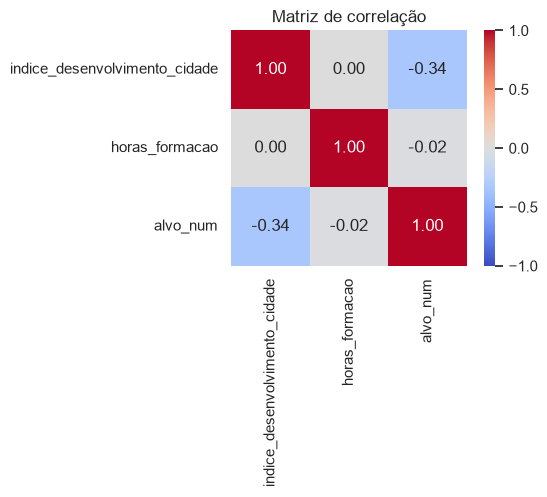

In [44]:
plt.figure(figsize=(6, 5))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, square=True)
plt.title("Matriz de correlação")
plt.tight_layout()
guardar_figura("02-5.3-matriz_correlacao")
plt.show()

##### Análise e Interpretação

> *Que variáveis estão mais correlacionadas com o alvo? E entre si?*

**Resposta:**

- correlação com o alvo: o `indice_desenvolvimento_cidade` é a variável mais correlacionada com o alvo (r = -0,34): quanto mais baixo o índice da cidade, maior a probabilidade de o candidato procurar mudar de emprego. É uma correlação negativa moderada, coerente com o que vimos nos boxplots (5.1) e com a hipótese H2. A `horas_formacao` tem uma correlação praticamente nula com o alvo (r = -0,02), o que confirma que quase não ajuda a separar as classes (H3 não confirmada)
- correlação entre as variáveis explicativas: o índice e as horas de formação quase não estão correlacionados entre si (r ≈ 0,00), por isso não há multicolinearidade entre as numéricas

- a correlação de Pearson mede apenas relações lineares. Como o alvo é binário (0/1), este valor é a chamada correlação ponto-bisserial. Com a correlação de Spearman, que não assume linearidade, os valores ficam parecidos (índice vs alvo: -0,28; horas vs alvo: -0,01), o que reforça a conclusão. Além disso, esta matriz só inclui as numéricas: variáveis como `anos_experiencia` ou `experiencia_relevante`, que mostraram taxas muito diferentes no 5.2, não aparecem por serem categóricas


<hr>

**5.4 Multicolinearidade**
- Listar os pares de variáveis explicativas com |r| > 0,8.

In [45]:
corr_expl = df[num_cols].corr()

# Ficar só com o triângulo superior, para cada par aparecer uma vez
triangulo = corr_expl.where(np.triu(np.ones(corr_expl.shape, dtype=bool), k=1))

# Transformar em lista de pares e filtrar |r| > 0,8
pares = triangulo.stack().reset_index()
pares.columns = ["variavel_1", "variavel_2", "r"]
fortes = pares[pares["r"].abs() > 0.8]

print("Pares com |r| > 0,8:")
display(fortes if len(fortes) > 0 else "Nenhum par ultrapassa 0,8")

# Todos os pares, ordenados, para teres a perspetiva completa
display(pares.sort_values("r", key=abs, ascending=False).round(3))

Pares com |r| > 0,8:


'Nenhum par ultrapassa 0,8'

,variavel_1,variavel_2,r
1,indice_desenvolvimento_cidade,horas_formacao,0.002
0,indice_desenvolvimento_cidade,indice_desenvolvimento_cidade,NaN
2,horas_formacao,indice_desenvolvimento_cidade,NaN
3,horas_formacao,horas_formacao,NaN


##### Análise e Interpretação

> *Há variáveis redundantes? Qual manteriam e porquê?*

**Resposta:**

- não há multicolinearidade entre as numéricas. O único par possível (`indice_desenvolvimento_cidade` e `horas_formacao`) tem r ≈ 0,00, muito abaixo do limite de 0,8. Nenhuma das duas é redundante, e podem manter-se as duas!
- já vimos anteriormente que existe redundância entre `cidade` e `indice_desenvolvimento_cidade`: cada cidade tem sempre o mesmo valor de índice, por isso o índice é uma característica da cidade e a informação do índice está contida na cidade.

- manteria o `indice_desenvolvimento_cidade`, porque é numérico, tem um efeito claro sobre o alvo (r = -0,34) e ocupa uma só coluna, enquanto a cidade tem 123 categorias (alta cardinalidade) e exigiria muitas colunas na codificação. A cidade pode ser testada como alternativa na modelação, mas o índice parece suficiente


<hr>

<div style="border-left:5px solid #0A2540;background:#F5F7FA;color:#1F2A37;padding:10px 16px;margin:6px 0;border-radius:3px;font-family:Segoe UI, Arial, sans-serif;"><div style="font-weight:700;color:#0A2540;font-size:13px;letter-spacing:0.5px;text-transform:uppercase;margin-bottom:4px;">Visto nas aulas</div>Correlação usa-se de forma <b>crítica</b>: mede apenas relação <b>linear</b> (Pearson) ou monótona (Spearman), é sensível a outliers e <b>correlação não implica causalidade</b>.</div>

#### 5.5 Testes estatísticos (opcional, valorizado)

| Situação | Teste | Hipótese nula (H0) |
|---|---|---|
| Numérica vs target binário | teste t (Welch) / Mann-Whitney | as médias/distribuições são iguais nas duas classes |
| Numérica vs target com 3+ classes | ANOVA / Kruskal-Wallis | as médias são iguais em todos os grupos |
| Categórica vs target categórico | Qui-quadrado | as variáveis são independentes |
| Categórica vs target numérico | teste t (2 grupos) / ANOVA (3+ grupos) | a média do target é igual em todos os grupos |
| Numérica vs target numérico | correlação de Pearson / Spearman (secção 5.1) | — |

Regra de decisão: se **p-value < 0,05**, rejeita-se H0 (a diferença/relação é estatisticamente significativa).

Cuidados (M2.05): o t-test pressupõe normalidade (ou n grande) → usar `equal_var=False` (Welch); a ANOVA diz que *pelo menos um* grupo difere, mas não qual; o qui-quadrado exige frequências esperadas ≥ 5. Alternativas não paramétricas: **Mann-Whitney**, **Kruskal-Wallis**, **Spearman**.

**5.5.1 [Classificação] Intervalos de confiança (M2.05)**
- Para cada numérica e cada classe: n, média e IC 95% (`stats.t.interval` com `stats.sem`).

In [46]:
linhas = []
for col in num_cols:
    for classe, s in df.groupby(TARGET)[col]:
        s = s.dropna()
        ic_inf, ic_sup = stats.t.interval(0.95, len(s) - 1, loc=s.mean(), scale=stats.sem(s))
        linhas.append({
            "variavel": col, "classe": classe, "n": len(s),
            "media": round(s.mean(), 3),
            "IC95_inf": round(ic_inf, 3), "IC95_sup": round(ic_sup, 3),
        })

display(pd.DataFrame(linhas))

,variavel,classe,n,media,IC95_inf,IC95_sup
0,indice_desenvolvimento_cidade,Não,14381,0.853,0.851,0.855
1,indice_desenvolvimento_cidade,Sim,4777,0.756,0.752,0.760
2,horas_formacao,Não,14381,66.114,65.118,67.110
3,horas_formacao,Sim,4777,63.118,61.494,64.743


##### Análise e Interpretação

> *Os intervalos das classes sobrepõem-se? O que isso sugere?*

**Resposta:**

- `indice_desenvolvimento_cidade`: os intervalos não se sobrepõem e estão bem afastados (cerca de 0,85 para “Não” e 0,75 para “Sim”). Isto sugere uma diferença real entre as classes: quem procura mudar vive, em média, em cidades com índice de desenvolvimento mais baixo. Os intervalos são muito estreitos porque a amostra é grande (n > 4 000 em cada classe).
- `horas_formacao`: os intervalos também não se sobrepõem, mas por muito pouco: o limite inferior de “Não” (65,1) fica ligeiramente acima do limite superior de “Sim” (64,7), uma folga de menos de 0,4 horas. Isto sugere que a diferença nas médias (cerca de 3 horas) pode não ser fruto do acaso, mas é muito pequena na prática, face a uma dispersão de cerca de 60 horas. É estatisticamente detetável por a amostra ser grande, mas pouco relevante para a decisão.

Conclusão: o índice de desenvolvimento diferencia claramente as classes; as horas de formação diferem de forma marginal. O IC dá uma indicação, mas a confirmação formal faz-se com os testes de hipóteses das secções seguintes (Welch e Mann-Whitney).
Nota: o intervalo de confiança refere-se à média, e as horas de formação têm distribuição assimétrica; com n tão grande, a média é ainda assim bem estimada (pelo teorema do limite central).

<hr>

**5.5.2 [Classificação] Testes de diferença de médias (M2.05)**
- 2 classes: `stats.ttest_ind(..., equal_var=False)`; 3+ classes: `stats.f_oneway`.
- Tabela com estatística, p-value e conclusão (α = 0,05).

In [47]:
sim = df[df[TARGET] == "Sim"]
nao = df[df[TARGET] == "Não"]

sim = df[df[TARGET] == "Sim"]
nao = df[df[TARGET] == "Não"]

linhas = []
for col in num_cols:
    t, p = stats.ttest_ind(sim[col], nao[col], equal_var=False)   # Welch
    u, p_mw = stats.mannwhitneyu(sim[col], nao[col])              # alternativa não paramétrica
    # d de Cohen: diferença de médias em nº de desvios padrão (desvio padrão conjunto)
    dp = np.sqrt(((len(sim) - 1) * sim[col].var() + (len(nao) - 1) * nao[col].var()) / (len(sim) + len(nao) - 2))
    linhas.append({
        "variavel": col,
        "t_Welch": round(t, 3),
        "p_Welch": p,
        "p_MannWhitney": p_mw,
        "d_Cohen": round((sim[col].mean() - nao[col].mean()) / dp, 3),
        "conclusao_Welch": "Significativa" if p < 0.05 else "Não significativa",
        "conclusao_MW": "Significativa" if p_mw < 0.05 else "Não significativa",
    })

display(pd.DataFrame(linhas))

# Pressuposto de variâncias iguais (o Welch não precisa dele, mas é bom ver)
for col in num_cols:
    print(col, "| Levene p =", stats.levene(sim[col], nao[col]).pvalue)

,variavel,t_Welch,p_Welch,p_MannWhitney,d_Cohen,conclusao_Welch,conclusao_MW
0,indice_desenvolvimento_cidade,-43.298,0.000000,0.00000,-0.84,Significativa,Significativa
1,horas_formacao,-3.081,0.002067,0.05056,-0.05,Significativa,Não significativa


indice_desenvolvimento_cidade | Levene p = 0.0
horas_formacao | Levene p = 0.0007678895082277436


##### Análise e Interpretação

> *Em que variáveis a diferença entre classes é estatisticamente significativa? Os pressupostos do teste verificam-se?*

**Resposta:**

- `indice_desenvolvimento_cidade`: diferença claramente significativa. Os dois testes dão p < 0,001, por isso rejeita-se H0 (médias iguais). Quem procura mudar tem um índice médio mais baixo (0,756 vs 0,853). O tamanho do efeito é grande (d de Cohen ≈ -0,84), ou seja, a diferença é significativa e relevante na prática.
- `horas_formacao`: resultado ambíguo. O teste de Welch rejeita H0 (p = 0,002), mas o Mann-Whitney não (p = 0,051, ligeiramente acima de 0,05). O efeito é praticamente desprezável (d ≈ -0,05; diferença de cerca de 3 horas, com desvio padrão de cerca de 60). A diferença, a existir, é muito pequena, e não é suficiente para considerar a H3 confirmada; aliás, o sentido da diferença é contrário ao previsto na hipótese.
- Pressupostos:
- - Independência: cumpre-se, porque cada linha é um candidato diferente.
- - Normalidade: não se cumpre (Shapiro-Wilk rejeitou-a nas duas variáveis), mas com mais de 4 700 observações por classe o teste t é robusto, pelo teorema do limite central. Para confirmar, usou-se o Mann-Whitney, que não precisa de normalidade.
- - Variâncias iguais: não se cumprem (o teste de Levene dá p < 0,05 nas duas variáveis). Por isso usou-se a versão de Welch (equal_var=False), que não exige este pressuposto.


<hr>

**5.5.3 [Classificação] Qui-quadrado (M2.05)**
- Para cada categórica: `stats.chi2_contingency(pd.crosstab(...))` — estatística, graus de liberdade e p-value.

In [48]:
linhas = []
for col in cat_cols:
    # Os nulos entram como categoria própria ("Em falta")
    tabela = pd.crosstab(df[col].fillna("Em falta"), df[TARGET])
    chi2, p, gl, esperados = stats.chi2_contingency(tabela)

    # V de Cramér: tamanho do efeito (0 = sem associação, 1 = associação total)
    v = np.sqrt(chi2 / (tabela.values.sum() * (min(tabela.shape) - 1)))

    linhas.append({
        "variavel": col,
        "chi2": round(chi2, 1),
        "gl": gl,
        "p_value": p,
        "V_Cramer": round(v, 3),
        "%_celulas_esp<5": round((esperados < 5).mean() * 100, 1),
        "conclusao": "Associada" if p < 0.05 else "Sem associação",
    })

display(pd.DataFrame(linhas).sort_values("V_Cramer", ascending=False))

,variavel,chi2,gl,p_value,V_Cramer,%_celulas_esp<5,conclusao
0,cidade,2998.8,122,0.000000e+00,0.396,24.8,Associada
7,dimensao_empresa,1162.0,8,1.587453e-245,0.246,0.0,Associada
8,tipo_empresa,959.8,6,4.351920e-204,0.224,0.0,Associada
6,anos_experiencia,704.7,22,7.882248e-135,0.192,0.0,Associada
3,inscricao_universidade,463.5,3,3.809312e-100,0.156,0.0,Associada
2,experiencia_relevante,315.3,1,1.500663e-70,0.128,0.0,Associada
4,nivel_educacao,167.3,5,2.787357e-34,0.093,0.0,Associada
9,anos_desde_ultimo_emprego,162.0,6,2.244940e-32,0.092,0.0,Associada
1,genero,117.4,3,2.833049e-25,0.078,0.0,Associada
5,area_formacao,64.2,6,6.224537e-12,0.058,0.0,Associada


##### Análise e Interpretação

> *Que categóricas estão associadas ao alvo?*

**Resposta:**

- todas as 10 categóricas estão significativamente associadas ao alvo (p < 0,05 em todas). Mas, com quase 19 000 registos, o teste deteta qualquer associação, mesmo pequena, por isso a força da associação (V de Cramér) é mais informativa do que o p-value.

- associação mais forte: cidade (V = 0,40), seguida de dimensao_empresa (0,25), tipo_empresa (0,22), anos_experiencia (0,19), inscricao_universidade (0,16) e experiencia_relevante (0,13). Estas são as candidatas mais promissoras para a modelação.

- associação fraca: nivel_educacao, anos_desde_ultimo_emprego, genero e area_formacao têm V abaixo de 0,10. São estatisticamente significativas, mas pouco relevantes na prática, sobretudo area_formacao (V = 0,06) e genero (V = 0,08), o que confirma o que vimos no 5.2.

Atenção à dimensao_empresa e ao tipo_empresa: grande parte da associação vem da categoria “Em falta” (taxa de cerca de 40% contra cerca de 18% nos restantes, como visto na H6). Ao retirar os nulos, a associação continua significativa (p < 0,001), mas fica mais fraca.

Pressupostos: o qui-quadrado exige frequências esperadas ≥ 5 na grande maioria das células. Isso cumpre-se em 9 das 10 variáveis (0% das células abaixo de 5). A exceção é a cidade, com 24,8% das células abaixo de 5 (o mínimo esperado é de 0,2), porque tem 123 categorias e muitas são pequenas. O resultado da cidade deve ser lido com cautela. Agrupar as zonas pequenas numa categoria “Outras” resolveria o problema.

Nota: o qui-quadrado diz se há associação, não em que sentido; o sentido está nas taxas do 5.2.

<hr>

### 6. Análise multivariada
<hr>

**Exploração conjunta de múltiplas variáveis**
- Pairplot (com `hue=target`, se classificação)
- Scatter plots com `hue` / `size` para ver 3 ou 4 variáveis em simultâneo
- Tabelas dinâmicas (duas categóricas vs target)
- Relações não lineares visíveis? Padrões ou agrupamentos naturais? Classes separáveis?

***Objetivo:*** identificar padrões complexos e perceber como as variáveis interagem entre si.

**6.1 Pairplot**
- `sns.pairplot` com as principais numéricas (até 6) e `hue=TARGET` em classificação.

Figura guardada em: Data\analytics\02-6.1-pairplot.png


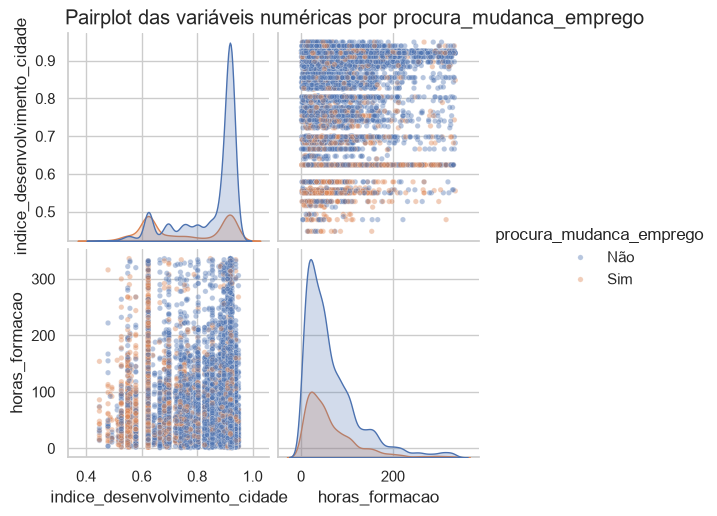

In [49]:
cols_pairplot = num_cols[:6]

# Pairplot com cor por classe do target
g = sns.pairplot(
    df,
    vars=cols_pairplot,
    hue=TARGET,
    diag_kind="kde",        # curvas de densidade na diagonal
    plot_kws={"alpha": 0.4, "s": 15},   # pontos transparentes e pequenos
    corner=False
)
g.figure.suptitle("Pairplot das variáveis numéricas por " + TARGET, y=1.02)
guardar_figura("02-6.1-pairplot")
plt.show()

Figura guardada em: Data\analytics\02-6.1-pairplot_amostra.png


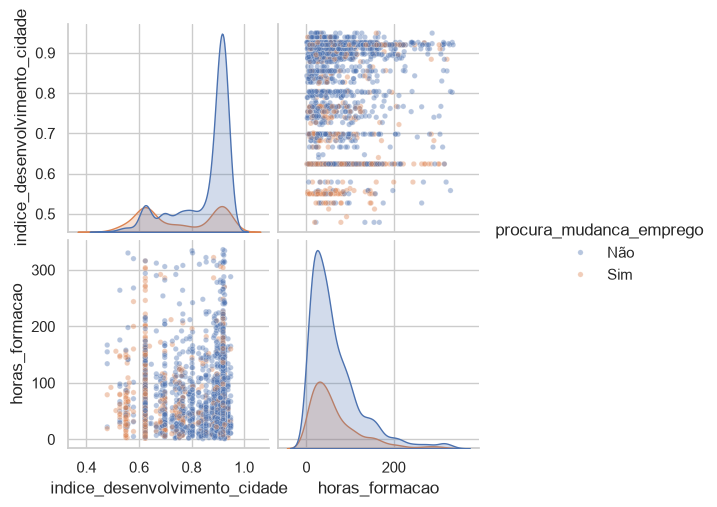

In [50]:
df_amostra = df.sample(3000, random_state=RANDOM_STATE)
sns.pairplot(df_amostra, vars=cols_pairplot, hue=TARGET, diag_kind="kde",
             plot_kws={"alpha": 0.4, "s": 15})
guardar_figura("02-6.1-pairplot_amostra")
plt.show()

In [51]:
# taxa de "Sim" por escalão: quintis do índice (limites repetidos em 0,92 juntam dois, ficam 4 grupos) e tercis das horas
display((y.groupby(pd.qcut(df["indice_desenvolvimento_cidade"], 5, duplicates="drop"), observed=True).mean() * 100).round(1))
display((y.groupby(pd.qcut(df["horas_formacao"], 3), observed=True).mean() * 100).round(1))

indice_desenvolvimento_cidade
(0.447, 0.691]    55.1
(0.691, 0.878]    20.6
(0.878, 0.92]     17.8
(0.92, 0.949]     10.4
Name: procura_mudanca_emprego, dtype: float64

horas_formacao
(0.999, 30.0]    25.3
(30.0, 71.0]     25.5
(71.0, 336.0]    24.0
Name: procura_mudanca_emprego, dtype: float64

##### Análise e Interpretação

> *Há pares de variáveis que separam bem as classes ou relações não lineares?*

**Resposta:**

- Sim, há separação parcial entre as classes, mas vem quase toda de uma única variável: `indice_desenvolvimento_cidade`. Na diagonal, a curva de "Sim" está deslocada para valores mais baixos do índice (mediana 0,74 contra 0,91 em "Não"), o que confirma a H2: candidatos de cidades menos desenvolvidas procuram mais mudar de emprego. A taxa de "Sim" é cerca de 55% no grupo de cidades com índice mais baixo e desce para cerca de 10% no grupo com índice mais alto.
- `horas_formacao` separa muito mal as classes: as distribuições de "Sim" e "Não" quase se sobrepõem (mediana de 46 contra 48 horas, e taxa de "Sim" entre 24% e 26% em todos os escalões). Por isso, a H3 não é confirmada nesta análise.
- No scatter `indice_desenvolvimento_cidade` × `horas_formacao`, não se vê nenhuma relação entre as duas variáveis (correlação ≈ 0,002) nem agrupamentos claros por classe. Os pontos formam colunas verticais porque o índice toma poucos valores distintos (é um valor por cidade).
- A relação entre o índice e o target parece não linear: a taxa de "Sim" desce muito do grupo mais baixo para o seguinte (55% → 21%) e depois mais suavemente. Isto é um padrão em degrau, não uma reta.

- Conclusão: as duas variáveis numéricas sozinhas separam só parcialmente as classes, e quem faz quase todo o trabalho é o índice de desenvolvimento da cidade. Para modelar bem, será importante incluir as variáveis categóricas (por exemplo `experiencia_relevante`, `tipo_empresa`).

<hr>

**6.2 Scatter com hue**
- Scatter de duas numéricas colorido pelo target (ou por uma categórica, em clustering).

Figura guardada em: Data\analytics\02-6.2-scatter_indice_horas.png


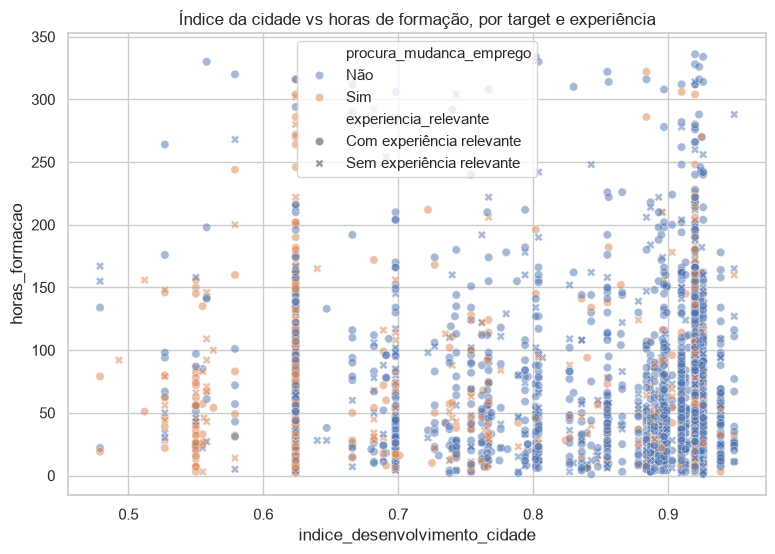

In [52]:
df_amostra = df.sample(3000, random_state=RANDOM_STATE)

plt.figure(figsize=(9, 6))
sns.scatterplot(
    data=df_amostra,
    x="indice_desenvolvimento_cidade",
    y="horas_formacao",
    hue=TARGET,                      # cor = target
    style="experiencia_relevante",   # forma do ponto = 3ª variável
    alpha=0.5
)
plt.title("Índice da cidade vs horas de formação, por target e experiência")
guardar_figura("02-6.2-scatter_indice_horas")
plt.show()

In [53]:
# taxa de "Sim" por nível do índice (baixo < 0,7 ≤ médio < 0,9 ≤ alto), cruzado com a experiência e com as horas
nivel_indice = pd.cut(df["indice_desenvolvimento_cidade"], [0, 0.7, 0.9, 1], right=False,
                      labels=["baixo", "médio", "alto"])
escalao_horas = pd.qcut(df["horas_formacao"], 3, labels=["poucas", "médias", "muitas"])

display((y.groupby([nivel_indice, df["experiencia_relevante"]], observed=True).mean() * 100).round(1).unstack())
display((y.groupby([nivel_indice, escalao_horas], observed=True).mean() * 100).round(1).unstack())

experiencia_relevante,Com experiência relevante,Sem experiência relevante
indice_desenvolvimento_cidade,,
baixo,50.1,52.7
médio,12.9,27.1
alto,13.6,26.0


horas_formacao,poucas,médias,muitas
indice_desenvolvimento_cidade,,,
baixo,51.3,52.0,49.7
médio,17.1,18.0,15.1
alto,16.8,17.1,16.6


##### Análise e Interpretação

> *O que se aprende ao ver três variáveis ao mesmo tempo?*

**Resposta:**

- dentro de cada grupo de experiência, a taxa de "Sim" é muito mais alta nas cidades com índice baixo (cerca de 50% a 53%) do que nas de índice médio ou alto (cerca de 13% a 27%).
- A experiência relevante tem efeito, mas depende do contexto: em cidades com índice médio ou alto, quem não tem experiência relevante procura mudar cerca de o dobro (26% a 27% contra 13% a 14%), o que confirma a H1. Já nas cidades com índice baixo, a diferença quase desaparece (53% contra 50%), porque aí a procura de mudança já é alta para toda a gente. Isto é uma interação entre variáveis, que não se via ao analisar cada uma isolada.
- O eixo `horas_formacao` não acrescenta separação: em todos os níveis do índice, a taxa de "Sim" é praticamente igual para poucas, médias e muitas horas de formação. No scatter, as cores ficam misturadas na vertical.
- Visualmente, o gráfico mostra colunas verticais (o índice toma poucos valores), e a cor "Sim" concentra-se nas colunas da esquerda (índices baixos).

- Conclusão: a análise a três variáveis mostra que o `indice_desenvolvimento_cidade` e a `experiencia_relevante` interagem, e que `horas_formacao` pesa pouco. Isto sugere que modelos capazes de captar interações (como Decision Tree ou Random Forest) podem ter vantagem sobre modelos lineares.

<hr>

**6.3 [Classificação] Duas categóricas vs target**
- `pivot_table` com a taxa média do target cruzando duas categóricas e heatmap.

Figura guardada em: Data\analytics\02-6.3-pivot_experiencia_educacao.png


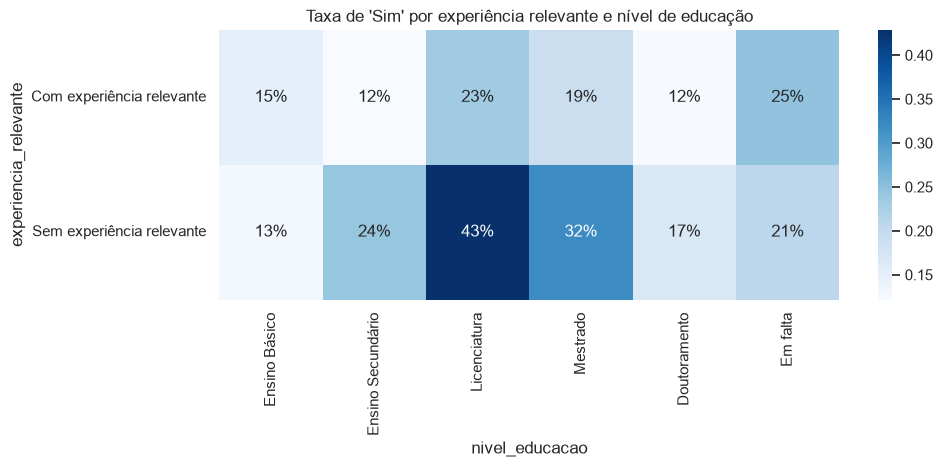

In [54]:
# experiencia_relevante × nivel_educacao

tmp = df.copy()   # cópia, para não acrescentar colunas ao df original
tmp["target_bin"] = (tmp[TARGET] == "Sim").astype(int)   # Sim = 1, Não = 0

# "Em falta" passa a ser uma categoria visível (senão o pandas ignora os NaN)
tmp["nivel_educacao"] = tmp["nivel_educacao"].fillna("Em falta")

ordem = ["Ensino Básico", "Ensino Secundário", "Licenciatura",
         "Mestrado", "Doutoramento", "Em falta"]

pivot = tmp.pivot_table(
    values="target_bin",
    index="experiencia_relevante",
    columns="nivel_educacao",
    aggfunc="mean"          # média de 0/1 = taxa de "Sim"
)[ordem]

plt.figure(figsize=(10, 3.5))
sns.heatmap(pivot, annot=True, fmt=".0%", cmap="Blues")
plt.title("Taxa de 'Sim' por experiência relevante e nível de educação")
guardar_figura("02-6.3-pivot_experiencia_educacao")
plt.show()

Figura guardada em: Data\analytics\02-6.3-pivot_tipo_dimensao_empresa.png


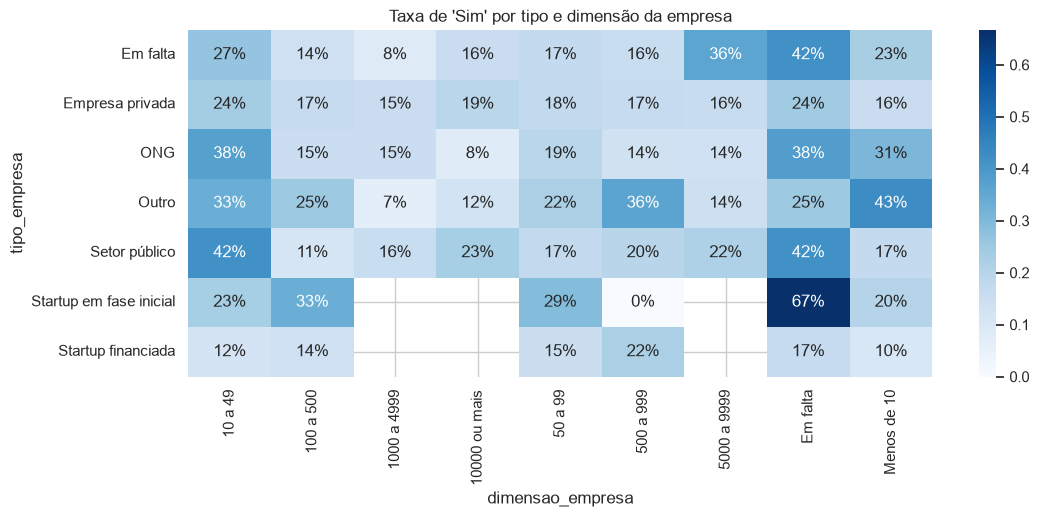

In [55]:
# tipo_empresa × dimensao_empresa (nulos como categoria própria)
tmp["tipo_empresa"] = tmp["tipo_empresa"].fillna("Em falta")
tmp["dimensao_empresa"] = tmp["dimensao_empresa"].fillna("Em falta")

pivot2 = tmp.pivot_table(values="target_bin", index="tipo_empresa",
                         columns="dimensao_empresa", aggfunc="mean")

plt.figure(figsize=(12, 4.5))
sns.heatmap(pivot2, annot=True, fmt=".0%", cmap="Blues")
plt.title("Taxa de 'Sim' por tipo e dimensão da empresa")
guardar_figura("02-6.3-pivot_tipo_dimensao_empresa")
plt.show()

##### Análise e Interpretação

> *Há combinações de categorias com comportamentos muito diferentes (interações)?*

**Resposta:**

- Sim, há combinações com comportamentos muito diferentes, o que indica interações entre variáveis. O exemplo mais claro é o cruzamento entre `experiencia_relevante` e `nivel_educacao`: quem tem Licenciatura mas não tem experiência relevante procura mudar em cerca de 43% dos casos, contra 23% de quem tem Licenciatura com experiência relevante. No Mestrado a diferença é semelhante (32% contra 19%) e no Ensino Secundário também (24% contra 12%).
- O efeito da experiência não é igual em todos os níveis: no Ensino Básico e no Doutoramento a diferença é pequena ou até inverte (13% contra 15% no Básico), mas esses grupos são pequenos e menos fiáveis. Quem não tem experiência relevante e tem Licenciatura é a célula mais "quente" do mapa, e quem tem experiência e Secundário, Doutoramento ou Básico é das mais "frias" (12% a 15%).
- Isto confirma a H1 (sem experiência relevante procura-se mais mudar), mas mostra que ela se manifesta sobretudo em quem tem Licenciatura ou Mestrado, que são também os grupos maiores.
- No cruzamento `tipo_empresa` × `dimensao_empresa` (segundo heatmap), a combinação com dados em falta nas duas colunas tem taxas altas (cerca de 42%, contra cerca de 18% da maioria das empresas privadas). Isto reforça a H6: a ausência de informação sobre a empresa está associada a maior procura de mudança, o que pode corresponder a pessoas sem emprego atual.
- Alguns grupos têm muito poucos casos (por exemplo, startups grandes ou "Outro"), pelo que as suas taxas não devem ser interpretadas isoladamente.
- Conclusão: as variáveis categóricas não atuam sozinhas, as suas combinações importam. Isto justifica usar modelos que captem interações (árvores, Random Forest) e manter os valores em falta como categoria própria na preparação dos dados.
 
<hr>

**6.4 Visão em 2D com PCA**
- Normalizar as numéricas (`StandardScaler`), projetar em 2 componentes (`PCA`) e fazer um scatter PC1 vs PC2 (colorido pelo target em classificação).

Variância explicada por componente: [0.501 0.499]
Variância explicada total: 1.0

Loadings:
                                 PC1    PC2
indice_desenvolvimento_cidade  0.707 -0.707
horas_formacao                 0.707  0.707
Figura guardada em: Data\analytics\02-6.4-pca_2d.png


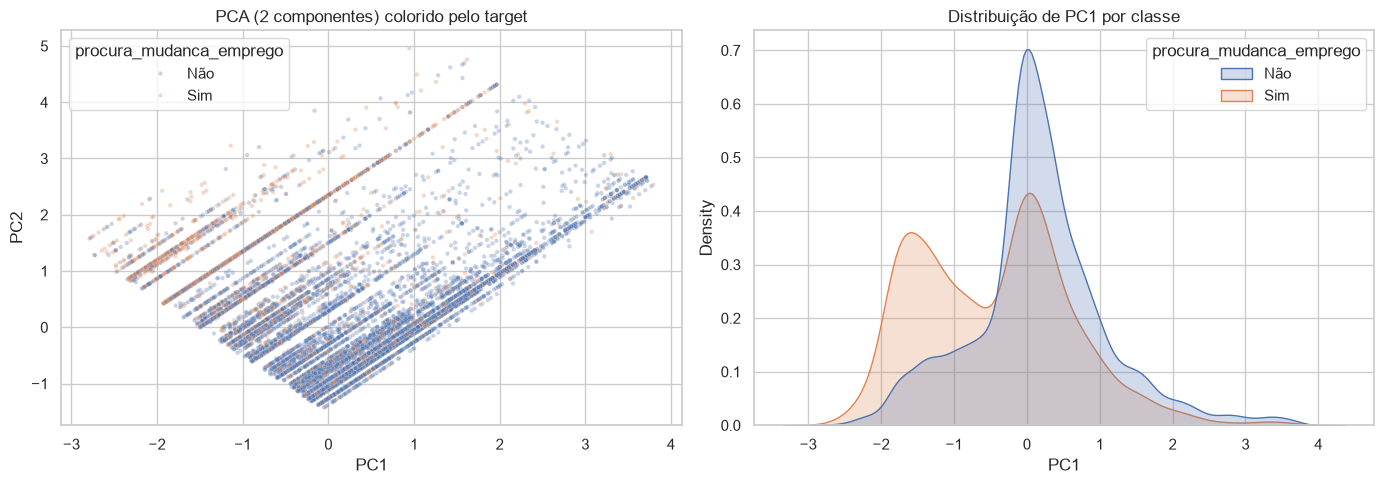

In [56]:
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

# 1. Selecionar as numéricas (não têm nulos, por isso não é preciso tratar)
X_num = df[num_cols].copy()

# 2. Normalizar: média 0 e desvio-padrão 1 em cada coluna
#    (sem isto, horas_formacao, com valores até ~300, dominaria o índice, entre 0 e 1)
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_num)

# 3. Projetar em 2 componentes
pca = PCA(n_components=2, random_state=RANDOM_STATE)
X_pca = pca.fit_transform(X_scaled)

# 4. Juntar num DataFrame com o target, para colorir o gráfico
pca_df = pd.DataFrame(X_pca, columns=["PC1", "PC2"])
pca_df[TARGET] = df[TARGET].values

# 5. Quanto da variância explica cada componente?
print("Variância explicada por componente:", pca.explained_variance_ratio_.round(3))
print("Variância explicada total:", pca.explained_variance_ratio_.sum().round(3))

# 6. Loadings: quanto pesa cada variável original em cada componente
loadings = pd.DataFrame(pca.components_.T, index=num_cols, columns=["PC1", "PC2"])
print("\nLoadings:")
print(loadings.round(3))

# 7. Gráficos: scatter PC1 vs PC2 + distribuição de PC1 por classe
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.scatterplot(
    data=pca_df, x="PC1", y="PC2", hue=TARGET,
    hue_order=["Não", "Sim"], alpha=0.3, s=10, ax=axes[0]
)
axes[0].set_title("PCA (2 componentes) colorido pelo target")

sns.kdeplot(
    data=pca_df, x="PC1", hue=TARGET, hue_order=["Não", "Sim"],
    common_norm=False, fill=True, ax=axes[1]
)
axes[1].set_title("Distribuição de PC1 por classe")

plt.tight_layout()
guardar_figura("02-6.4-pca_2d")
plt.show()

##### Análise e Interpretação

> *Existem agrupamentos naturais? As classes parecem separáveis?*

**Resposta:**

- Nota - só existem 2 variáveis numéricas (`indice_desenvolvimento_cidade` e `horas_formacao`), por isso o PCA com 2 componentes não reduz dimensionalidade: apenas roda os eixos. Os 2 componentes explicam 100% da variância.
- Variância explicada: cada componente explica cerca de 50% (PC1 ≈ 50,1% e PC2 ≈ 49,9%). Isto acontece porque as duas variáveis praticamente não estão correlacionadas (r ≈ 0,00 na secção 5.3): não há uma direção "dominante" nos dados.
- Loadings: PC1 e PC2 são combinações das duas variáveis com pesos semelhantes (em módulo), por isso nenhum componente tem uma interpretação simples isolada.
- Agrupamentos naturais: não se veem grupos bem definidos. Aparecem faixas/concentrações associadas aos picos do índice (~0,62 e ~0,92, distribuição multimodal da secção 4) e uma cauda longa causada pelos valores altos de `horas_formacao`.
- Separabilidade das classes: as classes sobrepõem-se bastante. Os "Sim" concentram-se mais na zona que corresponde a índice baixo, mas há muitos "Não" na mesma zona. Não existe uma fronteira clara entre classes.
- Conclusão: só com as variáveis numéricas não é possível separar bem quem procura mudar de emprego. O índice ajuda (já se tinha visto: d de Cohen ≈ -0,84), mas o modelo vai precisar das variáveis categóricas (experiência, dimensão e tipo de empresa, dados em falta...) para ter um desempenho razoável.

- Possível repetição na Fase 3 - depois de converter `anos_experiencia` e `anos_desde_ultimo_emprego` para numéricas e codificar as categóricas, o PCA passa a fazer sentido como redução de dimensionalidade e pode mostrar uma separação diferente.

<hr>

### 7. Síntese da Fase de Data Understanding
<hr>

**Principais padrões identificados**
- Variáveis potencialmente mais relevantes (com evidência: gráfico, correlação, teste)
- Problemas encontrados (missing, duplicados, inconsistências, outliers, desbalanceamento, multicolinearidade)
- Hipóteses da Fase 1 confirmadas / rejeitadas
- Estrutura dos dados (linhas independentes, várias linhas por entidade, ordem temporal) e variáveis com risco de *data leakage*
- Hipóteses iniciais sobre o tipo de modelo adequado (relações lineares ou não lineares?)

#### Decisões para a fase seguinte

| Problema / observação | Evidência (secção) | Decisão para a Fase 3 |
|---|---|---|
| ex.: `Intern_ID` é identificador | 2 | remover das features |
| ex.: `Salary` assimétrica à direita | 4.1 | testar `log1p` / RobustScaler |
| ex.: classes 70/30 | 4.8 | `stratify=y`; avaliar com F1 e ROC-AUC |
| ex.: `Data_Saida` só é conhecida depois do desfecho | 2.3 | remover das features (*data leakage*) |
| | | |

***Objetivo:*** traduzir a análise exploratória em decisões para a Data Preparation.

**Resposta:**

**1. Variáveis potencialmente mais relevantes**

| Variável | Evidência |
|---|---|
| `indice_desenvolvimento_cidade` | Média Sim 0,756 vs Não 0,853 (5.1); r = -0,34 com o alvo (5.3); IC 95% sem sobreposição (5.5.1); Welch e Mann-Whitney p < 0,001, d de Cohen ≈ -0,84, efeito grande (5.5.2) |
| `cidade` | V de Cramér 0,40, o mais alto (5.5.3), mas redundante com o índice e com 24,8% de células com esperado < 5 |
| `dimensao_empresa`, `tipo_empresa` | V de Cramér 0,25 e 0,22 (5.5.3); taxa de "Sim" ~39–41% quando estão em falta vs ~18% (5.2) |
| `anos_experiencia` | V = 0,19; 45,4% de "Sim" com menos de 1 ano vs ~15% com mais de 15 anos (5.2) |
| `inscricao_universidade` | V = 0,16; 38,1% de "Sim" em curso a tempo inteiro vs 21,1% (5.2) |
| `experiencia_relevante` | V = 0,13; 33,8% vs 21,5% (5.2) |
| Nº de nulos por linha | 16,6% de "Sim" sem nulos vs 41,5% com 2 nulos (3.2) |

Variáveis fracas: `horas_formacao` (r = -0,02; d ≈ -0,05, efeito desprezável; Mann-Whitney p = 0,051), `genero` (V = 0,08) e `area_formacao` (V = 0,06). São estatisticamente associadas ao alvo, mas com efeito muito pequeno (com n = 19 158, quase tudo dá p < 0,05).

**2. Problemas encontrados**

- **Missing:** 8 colunas com nulos; os mais graves são `tipo_empresa` (32,05%), `dimensao_empresa` (30,99%), `genero` (23,53%) e `area_formacao` (14,68%). 53,3% das linhas têm pelo menos um nulo. Os nulos não são aleatórios: os da empresa aparecem juntos e estão associados a não ter experiência relevante (compatível com MAR); os de `area_formacao` são estruturais (quem não tem ensino superior não tem área). A própria ausência de dados é informativa para o alvo.
- **Duplicados:** não há linhas nem IDs duplicados; os 49 duplicados ignorando o ID são candidatos distintos (mantêm-se).
- **Inconsistências:** não há valores impossíveis nem categorias escritas de formas diferentes. Há problemas de formato: `anos_experiencia` e `anos_desde_ultimo_emprego` são quantidades guardadas como texto.
- **Outliers:** 984 em `horas_formacao` pelo IQR (5,1%), mas são valores reais e plausíveis. Distribuição assimétrica (skew 1,82) que o `log1p` corrige (skew -0,35).
- **Categorias raras e cardinalidade alta:** várias categorias < 5% (Ensino Básico, Doutoramento, "Outro", Artes); `cidade` com 123 categorias, 106 delas com < 1%.
- **Desbalanceamento:** Não 75,1% / Sim 24,9% (rácio ~3:1). Um modelo que diga sempre "Não" acerta 75,1%, por isso a accuracy não serve como métrica principal.
- **Multicolinearidade:** não há (nenhum par com |r| > 0,8; índice vs horas r ≈ 0,00). A única redundância é `cidade` ↔ índice.
- **Escalas diferentes:** índice entre 0 e 1, horas até centenas; nenhuma variável é normal (Shapiro-Wilk, QQ-plots).

**3. Hipóteses da Fase 1**

| # | Hipótese | Veredicto |
|---|---|---|
| H1 | Sem experiência relevante procuram mais mudar | Confirmada (33,8% vs 21,5%) |
| H2 | Cidades menos desenvolvidas procuram mais mudar | Confirmada (efeito grande, d ≈ -0,84) |
| H3 | Mais horas de formação, mais abertos a mudar | Rejeitada (diferença mínima e no sentido contrário: 63,1 vs 66,1 horas) |
| H4 | Menos anos de experiência procuram mais mudar | Confirmada (45,4% com < 1 ano vs ~15% com > 15 anos) |
| H5 | Startups e empresas pequenas procuram mais mudar | Parcialmente rejeitada / inconclusiva (startups financiadas têm a taxa mais baixa, 14,0%; "Menos de 10" tem 17,1%) |
| H6 | Falta de dados da empresa associada a outra taxa | Confirmada (38,0% vs 17,9%) |

**4. Estrutura dos dados e data leakage**

- Cada linha é um candidato diferente (sem IDs repetidos, sem várias linhas por entidade) e não há ordem temporal. As linhas são independentes, por isso a divisão aleatória estratificada é adequada.
- Não foi identificada nenhuma variável com risco de data leakage: todas descrevem o candidato no momento em que responde (perfil, formação, empresa atual), não algo que só se sabe depois de ele mudar ou não de emprego.
- `id_candidato` é apenas um identificador e não deve entrar no modelo.

**5. Hipóteses sobre o tipo de modelo**

- As relações parecem **não lineares**: o índice é multimodal, o efeito dos anos de experiência não é uma linha reta e a informação está sobretudo em variáveis categóricas (incluindo o facto de um valor estar em falta). A visão em 2D com PCA (6.4) mostra muita sobreposição entre classes usando só as numéricas.
- Proposta: **regressão logística** como baseline (simples e interpretável, exige escalonamento e codificação) e modelos baseados em **árvores** (Decision Tree, Random Forest, Gradient Boosting), que lidam bem com relações não lineares, interações e categorias, e não precisam de escalonamento.
- Dado o desbalanceamento, avaliar com recall, precision, F1 e ROC-AUC da classe "Sim", e testar `class_weight="balanced"`.

#### Decisões para a fase seguinte

| Problema / observação | Evidência (secção) | Decisão para a Fase 3 |
|---|---|---|
| `id_candidato` é identificador | 2.3 | Remover das features |
| `cidade` redundante com o índice e com 123 categorias | 2.3, 4, 5.5.3 | Usar o índice; testar `cidade` com zonas pequenas agrupadas em "Outras" como alternativa |
| Nulos em 8 colunas, não aleatórios e informativos | 3.1–3.3, 5.2 | Não usar `dropna()`; nulos como categoria própria ("Em falta" / "Não aplicável" em `area_formacao`) |
| Falta de dados da empresa associada ao alvo | 3.2, 5.2 (H6) | Criar `empresa_em_falta` (0/1) e eventualmente nº de nulos por linha |
| `anos_experiencia` e `anos_desde_ultimo_emprego` como texto | 2, 3.5 | Converter para numéricas ("Menos de 1 ano" → 0, "Mais de 20 anos" → 21, "Mais de 4 anos" → 5, "Nunca" → 0) |
| `dimensao_empresa` e `nivel_educacao` têm ordem | 3.5 | Codificação ordinal com ordem definida manualmente |
| Restantes categóricas sem ordem | 4 | One-hot encoding |
| Categorias raras (< 5%) | 4 | Agrupar em "Outro" quando fizer sentido |
| `horas_formacao` assimétrica à direita, com outliers reais | 4 | Manter outliers; criar `horas_formacao_log` com `np.log1p` |
| Escalas muito diferentes e variáveis não normais | 4 | `StandardScaler` (ou `RobustScaler`) para logística/KNN; ajustado só no treino |
| Classes 75/25 | 4 | `train_test_split(..., stratify=y)`; StratifiedKFold; F1, recall e ROC-AUC da classe "Sim"; testar `class_weight="balanced"` |
| `horas_formacao`, `genero`, `area_formacao` com efeito fraco | 5.3, 5.5.2, 5.5.3 | Manter numa primeira versão; avaliar a remoção com a importância das variáveis |
| Sem multicolinearidade nem data leakage | 2, 5.4 | Nenhuma remoção adicional necessária |
| Linhas independentes, sem ordem temporal | 3.3 | Divisão aleatória estratificada (`TEST_SIZE = 0.2`, `RANDOM_STATE = 42`) |

***Objetivo:*** traduzir a análise exploratória em decisões para a Data Preparation.

<div style="border-left:5px solid #1A59FD;background:#F3F6FF;color:#1F2A37;padding:10px 16px;margin:6px 0;border-radius:3px;font-family:Segoe UI, Arial, sans-serif;"><div style="font-weight:700;color:#1A59FD;font-size:13px;letter-spacing:0.5px;text-transform:uppercase;margin-bottom:4px;">Antes de avançar</div>Checklist de autoavaliação da fase<ul style="margin:4px 0 2px 0;"><li>Dataset descrito (origem, dimensão, dicionário de dados)</li><li>Estrutura e tipos verificados; identificadores e colunas irrelevantes assinalados</li><li>Qualidade avaliada: missing, duplicados, inconsistências</li><li>Análise univariada com interpretação (incluindo o target)</li><li>Análise bivariada e multivariada com interpretação</li><li>Gráficos adequados ao tipo de variável, com títulos e eixos legíveis</li><li>Variáveis com risco de <i>data leakage</i> e estrutura dos dados (grupos / tempo) identificadas</li><li>Síntese com decisões concretas para a Fase 3</li></ul></div>

[← Fase 1: Entendimento do Negócio](01_business_understanding.ipynb) &nbsp;&nbsp;|&nbsp;&nbsp; [Fase 3: Preparação dos Dados →](03_data_preparation.ipynb)

<div style="border-left:7px solid #1A59FD; background:#F3F6FF; color:#0A2540; padding:6px 14px; border-radius:4px; font-size:12px; font-family:Segoe UI, Arial, sans-serif;">Cegid Academy &nbsp;·&nbsp; AiDAPT &nbsp;·&nbsp; Template CRISP-DM v2.0 · versão formandos</div>